In [10]:
!pip install -q importlib_resources

In [5]:
# =====================================================================
# BLOCK 1 : Imports | seed | font | config | Drive outputs | helpers
# =====================================================================
import os, time, json, random, math, warnings
from pathlib import Path
from collections import OrderedDict
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager as fm
from IPython.display import display

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications.resnet50 import preprocess_input
import tensorflow_datasets as tfds
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report)
warnings.filterwarnings("ignore", category=UserWarning)

# ---- reproducibility ------------------------------------------------
SEED = 42
os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED); np.random.seed(SEED); tf.keras.utils.set_random_seed(SEED)
gpus = tf.config.list_physical_devices("GPU")
for g in gpus:
    tf.config.experimental.set_memory_growth(g, True)
try:
    GPU_NAME = tf.config.experimental.get_device_details(gpus[0]).get("device_name", "GPU")
except Exception:
    GPU_NAME = "CPU"

# ---- font : Times New Roman 16 (times.ttf already in /content) ------
FONT_PATH = "/content/times.ttf"
assert os.path.exists(FONT_PATH), "upload times.ttf to /content"
fm.fontManager.addfont(FONT_PATH)
FONT_NAME = fm.FontProperties(fname=FONT_PATH).get_name()
plt.rcParams.update({
    "font.family": FONT_NAME, "font.size": 16, "axes.titlesize": 16,
    "axes.labelsize": 16, "xtick.labelsize": 16, "ytick.labelsize": 16,
    "legend.fontsize": 16, "figure.titlesize": 16, "mathtext.fontset": "stix",
    "axes.unicode_minus": False, "pdf.fonttype": 42, "ps.fonttype": 42,
    "figure.dpi": 100, "savefig.dpi": 300, "axes.grid": False})

# ---- config (identical for every run) -------------------------------
CFG = dict(seed=SEED, img_size=224, batch_size=32, num_classes=5,
           reduction_ratio=16, spatial_kernel=7, dropout=0.3,
           epochs_head=5, epochs_finetune=5,          # 10 epochs in total
           lr_head=1e-3, lr_finetune=1e-5,
           timing_warmup=10, timing_repeats=50)

POSITIONS = OrderedDict(
    P1=dict(layer="conv2_block3_out", hw=56, ch=256),
    P2=dict(layer="conv3_block4_out", hw=28, ch=512),
    P3=dict(layer="conv4_block6_out", hw=14, ch=1024),
    P4=dict(layer="conv5_block3_out", hw=7,  ch=2048))

# ---- Google Drive outputs -------------------------------------------
from google.colab import drive
drive.mount("/content/drive")
OUT_DIR = Path("/content/drive/MyDrive/CS3807_Exp8_9/outputs")
DIRS = {k: OUT_DIR / k for k in ["figures", "weights", "histories", "results"]}
for d in DIRS.values():
    d.mkdir(parents=True, exist_ok=True)

# ---- figure saver : EPS if < 100 KB else PDF -------------------------
EPS_LIMIT_BYTES = 100 * 1024
def save_fig(fig, name, show=True):
    eps, pdf = DIRS["figures"] / f"{name}.eps", DIRS["figures"] / f"{name}.pdf"
    for p in (eps, pdf):
        if p.exists(): p.unlink()
    fig.savefig(eps, format="eps", bbox_inches="tight")
    if eps.stat().st_size < EPS_LIMIT_BYTES:
        final = eps
    else:
        eps.unlink(); fig.savefig(pdf, format="pdf", bbox_inches="tight"); final = pdf
    print(f"[saved] {final.name} ({final.stat().st_size/1024:.1f} KB)")
    if show: plt.show()
    plt.close(fig)
    return final

# ---- results registry (persisted on Drive) ---------------------------
RESULTS = OrderedDict()
def save_results():
    with open(DIRS["results"] / "results.json", "w") as f:
        json.dump(RESULTS, f, indent=2, default=float)
    pd.DataFrame(RESULTS).T.to_csv(DIRS["results"] / "results.csv")
def load_results():
    p = DIRS["results"] / "results.json"
    if p.exists():
        with open(p) as f: RESULTS.update(json.load(f))
load_results()

print("TF", tf.__version__, "| GPU:", GPU_NAME, "| Font:", FONT_NAME,
      "| runs already on Drive:", len(RESULTS))

Mounted at /content/drive
TF 2.21.0 | GPU: Tesla T4 | Font: Times New Roman | runs already on Drive: 17


Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Generating splits...:   0%|          | 0/1 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/tf_flowers/incomplete.HBRPOI_3.0.1/tf_flowers-train.tfrecord-[0-9][0-9][0-…

Dataset tf_flowers downloaded and prepared to /root/tensorflow_datasets/tf_flowers/3.0.1. Subsequent calls will reuse this data.
[saved] fig01_sample_images.pdf (680.4 KB)


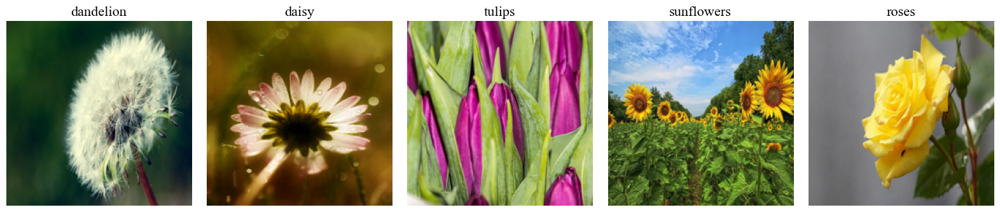

,Train,Val,Test
dandelion,629,134,135
daisy,443,95,95
tulips,559,120,120
sunflowers,489,105,105
roses,449,96,96
Total,2569,550,551


In [11]:
# =====================================================================
# BLOCK 2 : Dataset | stratified split | augmentation | pipelines
# =====================================================================
IMG, BS, NC = CFG["img_size"], CFG["batch_size"], CFG["num_classes"]
CACHE_NPZ = Path("/content/flowers_224_uint8.npz")      # local, quick to rebuild

if CACHE_NPZ.exists():
    _c = np.load(CACHE_NPZ, allow_pickle=True)
    X_all, y_all, CLASS_NAMES = _c["X"], _c["y"], [str(n) for n in _c["names"]]
else:
    raw, info = tfds.load("tf_flowers", split="train", as_supervised=True,
                          with_info=True, shuffle_files=False)
    CLASS_NAMES = list(info.features["label"].names)
    n = info.splits["train"].num_examples
    X_all = np.empty((n, IMG, IMG, 3), np.uint8); y_all = np.empty((n,), np.int64)
    for i, (img, lab) in enumerate(tfds.as_numpy(raw)):
        r = tf.image.resize(img, (IMG, IMG), method="bilinear", antialias=True)
        X_all[i] = tf.cast(tf.round(r), tf.uint8).numpy(); y_all[i] = lab
    np.savez(CACHE_NPZ, X=X_all, y=y_all, names=np.array(CLASS_NAMES))

idx = np.arange(len(y_all))
idx_train, idx_tmp = train_test_split(idx, test_size=0.30, stratify=y_all, random_state=SEED)
idx_val, idx_test  = train_test_split(idx_tmp, test_size=0.50, stratify=y_all[idx_tmp],
                                      random_state=SEED)
np.savez(DIRS["results"] / "split_indices.npz", train=idx_train, val=idx_val, test=idx_test)

X_train, y_train = X_all[idx_train], y_all[idx_train]
X_val,   y_val   = X_all[idx_val],   y_all[idx_val]
X_test,  y_test  = X_all[idx_test],  y_all[idx_test]

split_table = pd.DataFrame(
    {nm: [int((y == c).sum()) for c in range(NC)]
     for nm, y in [("Train", y_train), ("Val", y_val), ("Test", y_test)]},
    index=CLASS_NAMES)
split_table.loc["Total"] = split_table.sum()
split_table.to_csv(DIRS["results"] / "split_counts.csv")

augment = keras.Sequential([
    layers.RandomFlip("horizontal", seed=SEED),
    layers.RandomRotation(0.05, seed=SEED),
    layers.RandomZoom(0.10, seed=SEED),
    layers.RandomTranslation(0.10, 0.10, seed=SEED),
    layers.RandomContrast(0.10, seed=SEED)], name="augmentation")

AUTOTUNE = tf.data.AUTOTUNE
def _prep(x, y, training):
    x = tf.cast(x, tf.float32)
    if training:
        x = tf.clip_by_value(augment(x, training=True), 0.0, 255.0)
    return preprocess_input(x), tf.one_hot(y, NC)

def make_ds(X, y, training):
    ds = tf.data.Dataset.from_tensor_slices((X, y))
    if training:
        ds = ds.shuffle(len(X), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.batch(BS).map(lambda a, b: _prep(a, b, training), num_parallel_calls=AUTOTUNE)
    return ds.prefetch(AUTOTUNE)

train_ds = make_ds(X_train, y_train, True)
val_ds   = make_ds(X_val,   y_val,   False)
test_ds  = make_ds(X_test,  y_test,  False)     # fixed order for CM / Grad-CAM

# ---- required figure 1 : sample images from all five classes ---------
rng = np.random.RandomState(SEED)
fig, axes = plt.subplots(1, NC, figsize=(3.2 * NC, 3.6))
for c, ax in enumerate(axes):
    ax.imshow(X_train[rng.choice(np.where(y_train == c)[0])])
    ax.set_title(CLASS_NAMES[c]); ax.axis("off")
fig.tight_layout()
save_fig(fig, "fig01_sample_images")

split_table

In [14]:
# =====================================================================
# BLOCK 3 : All attention layers. Every layer preserves (H, W, C).
# Spatial -> Channel -> Sequential -> Self -> Combined -> CBAM -> ECA -> Coordinate
# =====================================================================
reg = tf.keras.utils.register_keras_serializable(package="attn")

# ---- Spatial : Ms = sigmoid(Conv_kxk([mean_c ; max_c])) -------------
@reg
class SpatialAttention(layers.Layer):
    def __init__(self, kernel_size=7, **kw):
        super().__init__(**kw)
        self.kernel_size = kernel_size
        self.conv = layers.Conv2D(1, kernel_size, padding="same", activation="sigmoid",
                                  use_bias=False, name="spatial_conv")
    def build(self, input_shape):
        self.conv.build(input_shape[:-1] + (2,))
        super().build(input_shape)
    def compute_map(self, x):                                  # (B,H,W,1)
        avg = tf.reduce_mean(x, axis=-1, keepdims=True)
        mx  = tf.reduce_max(x,  axis=-1, keepdims=True)
        return self.conv(tf.concat([avg, mx], axis=-1))
    def call(self, x):
        return x * self.compute_map(x)
    def compute_output_shape(self, s): return s
    def get_config(self):
        return {**super().get_config(), "kernel_size": self.kernel_size}

# ---- Channel (SE form) : sigmoid(W2 relu(W1 GAP(F))) ----------------
@reg
class ChannelAttention(layers.Layer):
    def __init__(self, reduction=16, **kw):
        super().__init__(**kw)
        self.reduction = reduction
    def build(self, input_shape):
        C = input_shape[-1]; h = max(C // self.reduction, 1)
        self.fc1 = layers.Dense(h, activation="relu", name="ch_fc1")
        self.fc2 = layers.Dense(C, activation="sigmoid", name="ch_fc2")
        self.fc1.build((None, C)); self.fc2.build((None, h))
        super().build(input_shape)
    def compute_weights(self, x):                              # (B,C)
        return self.fc2(self.fc1(tf.reduce_mean(x, axis=[1, 2])))
    def call(self, x):
        return x * self.compute_weights(x)[:, None, None, :]
    def compute_output_shape(self, s): return s
    def get_config(self):
        return {**super().get_config(), "reduction": self.reduction}

# ---- Sequential : "sc" = Spatial->Channel, "cs" = Channel->Spatial --
@reg
class SequentialAttention(layers.Layer):
    def __init__(self, order="sc", kernel_size=7, reduction=16, **kw):
        super().__init__(**kw)
        assert order in ("sc", "cs")
        self.order, self.kernel_size, self.reduction = order, kernel_size, reduction
        self.sa = SpatialAttention(kernel_size, name="sa")
        self.ca = ChannelAttention(reduction, name="ca")
    def build(self, input_shape):
        self.sa.build(input_shape); self.ca.build(input_shape)
        super().build(input_shape)
    def call(self, x):
        return self.ca(self.sa(x)) if self.order == "sc" else self.sa(self.ca(x))
    def trace(self, x):                                        # for visualisation cells
        out = {"input": x}
        if self.order == "sc":
            out["spatial_map"] = self.sa.compute_map(x)
            xs = x * out["spatial_map"]; out["after_first"] = xs
            out["channel_w"] = self.ca.compute_weights(xs)
            out["output"] = xs * out["channel_w"][:, None, None, :]
        else:
            out["channel_w"] = self.ca.compute_weights(x)
            xc = x * out["channel_w"][:, None, None, :]; out["after_first"] = xc
            out["spatial_map"] = self.sa.compute_map(xc)
            out["output"] = xc * out["spatial_map"]
        return out
    def compute_output_shape(self, s): return s
    def get_config(self):
        return {**super().get_config(), "order": self.order,
                "kernel_size": self.kernel_size, "reduction": self.reduction}

# ---- Self-attention : F + gamma * W_o(softmax(QK^T/sqrt(d)) V) ------
@reg
class SelfAttention(layers.Layer):
    def __init__(self, qk_divisor=8, v_divisor=2, **kw):
        super().__init__(**kw)
        self.qk_divisor, self.v_divisor = qk_divisor, v_divisor
    def build(self, input_shape):
        _, H, W, C = input_shape
        self.H, self.W, self.C, self.N = H, W, C, H * W
        self.dk, self.dv = max(C // self.qk_divisor, 1), max(C // self.v_divisor, 1)
        self.wq = layers.Dense(self.dk, use_bias=False, name="sa_q")
        self.wk = layers.Dense(self.dk, use_bias=False, name="sa_k")
        self.wv = layers.Dense(self.dv, use_bias=False, name="sa_v")
        self.wo = layers.Dense(C,       use_bias=False, name="sa_o")
        for l, d in [(self.wq, C), (self.wk, C), (self.wv, C), (self.wo, self.dv)]:
            l.build((None, self.N, d))
        self.gamma = self.add_weight(name="gamma", shape=(), initializer="zeros",
                                     trainable=True)
        super().build(input_shape)
    def _flat(self, x):
        return tf.reshape(x, [tf.shape(x)[0], self.N, self.C])
    def compute_attention(self, x):
        X = self._flat(x)
        s = tf.matmul(self.wq(X), self.wk(X), transpose_b=True)
        return tf.nn.softmax(s / math.sqrt(self.dk), axis=-1)
    def call(self, x):
        X = self._flat(x)
        Y = self.wo(tf.matmul(self.compute_attention(x), self.wv(X)))
        return x + self.gamma * tf.reshape(Y, tf.shape(x))
    def compute_output_shape(self, s): return s
    def get_config(self):
        return {**super().get_config(), "qk_divisor": self.qk_divisor,
                "v_divisor": self.v_divisor}

# ---- Combined (A5) : Spatial -> Channel -> Self-attention -----------
@reg
class CombinedAttention(layers.Layer):
    def __init__(self, kernel_size=7, reduction=16, **kw):
        super().__init__(**kw)
        self.kernel_size, self.reduction = kernel_size, reduction
        self.seq = SequentialAttention("sc", kernel_size, reduction, name="seq")
        self.selfatt = SelfAttention(name="selfatt")
    def build(self, input_shape):
        self.seq.build(input_shape); self.selfatt.build(input_shape)
        super().build(input_shape)
    def call(self, x):
        return self.selfatt(self.seq(x))
    def compute_output_shape(self, s): return s
    def get_config(self):
        return {**super().get_config(), "kernel_size": self.kernel_size,
                "reduction": self.reduction}

# ---- CBAM : channel (avg+max, shared MLP) -> spatial ----------------
@reg
class CBAM(layers.Layer):
    def __init__(self, reduction=16, kernel_size=7, **kw):
        super().__init__(**kw)
        self.reduction, self.kernel_size = reduction, kernel_size
        self.sa = SpatialAttention(kernel_size, name="cbam_sa")
    def build(self, input_shape):
        C = input_shape[-1]; h = max(C // self.reduction, 1)
        self.mlp1 = layers.Dense(h, activation="relu", name="cbam_fc1")
        self.mlp2 = layers.Dense(C, name="cbam_fc2")
        self.mlp1.build((None, C)); self.mlp2.build((None, h))
        self.sa.build(input_shape)
        super().build(input_shape)
    def compute_weights(self, x):
        a = self.mlp2(self.mlp1(tf.reduce_mean(x, axis=[1, 2])))
        m = self.mlp2(self.mlp1(tf.reduce_max(x,  axis=[1, 2])))
        return tf.sigmoid(a + m)
    def call(self, x):
        return self.sa(x * self.compute_weights(x)[:, None, None, :])
    def compute_output_shape(self, s): return s
    def get_config(self):
        return {**super().get_config(), "reduction": self.reduction,
                "kernel_size": self.kernel_size}

# ---- ECA : GAP -> 1-D conv across channels -> sigmoid ---------------
@reg
class ECA(layers.Layer):
    def __init__(self, gamma=2, b=1, **kw):
        super().__init__(**kw)
        self.gamma, self.b = gamma, b
    def build(self, input_shape):
        C = input_shape[-1]
        k = int(abs((math.log2(C) + self.b) / self.gamma))
        self.k = k if k % 2 == 1 else k + 1
        self.conv = layers.Conv1D(1, self.k, padding="same", use_bias=False, name="eca_conv")
        self.conv.build((None, C, 1))
        super().build(input_shape)
    def compute_weights(self, x):
        z = tf.reduce_mean(x, axis=[1, 2])[..., None]
        return tf.sigmoid(tf.squeeze(self.conv(z), -1))
    def call(self, x):
        return x * self.compute_weights(x)[:, None, None, :]
    def compute_output_shape(self, s): return s
    def get_config(self):
        return {**super().get_config(), "gamma": self.gamma, "b": self.b}

# ---- Coordinate attention (optional third extra mechanism) ----------
@reg
class CoordinateAttention(layers.Layer):
    def __init__(self, reduction=32, **kw):
        super().__init__(**kw)
        self.reduction = reduction
    def build(self, input_shape):
        _, H, W, C = input_shape
        self.H, self.W = H, W
        m = max(8, C // self.reduction)
        self.conv1  = layers.Conv2D(m, 1, name="coord_reduce")
        self.bn     = layers.BatchNormalization(name="coord_bn")
        self.conv_h = layers.Conv2D(C, 1, activation="sigmoid", name="coord_h")
        self.conv_w = layers.Conv2D(C, 1, activation="sigmoid", name="coord_w")
        self.conv1.build((None, H + W, 1, C)); self.bn.build((None, H + W, 1, m))
        self.conv_h.build((None, H, 1, m));    self.conv_w.build((None, W, 1, m))
        super().build(input_shape)
    def call(self, x):
        xh = tf.reduce_mean(x, axis=2, keepdims=True)                          # (B,H,1,C)
        xw = tf.transpose(tf.reduce_mean(x, axis=1, keepdims=True), [0, 2, 1, 3])  # (B,W,1,C)
        y = self.bn(self.conv1(tf.concat([xh, xw], axis=1)))
        y = y * tf.nn.relu6(y + 3.0) / 6.0                                     # h-swish
        yh, yw = tf.split(y, [self.H, self.W], axis=1)
        ah = self.conv_h(yh)                                                   # (B,H,1,C)
        aw = tf.transpose(self.conv_w(yw), [0, 2, 1, 3])                       # (B,1,W,C)
        return x * ah * aw
    def compute_output_shape(self, s): return s
    def get_config(self):
        return {**super().get_config(), "reduction": self.reduction}

# ---- factory ---------------------------------------------------------
def make_attention(kind, name, kernel=None, reduction=None):
    kernel    = kernel    or CFG["spatial_kernel"]
    reduction = reduction or CFG["reduction_ratio"]
    if kind == "spatial":    return SpatialAttention(kernel, name=name)
    if kind == "channel":    return ChannelAttention(reduction, name=name)
    if kind in ("sc", "cs"): return SequentialAttention(kind, kernel, reduction, name=name)
    if kind == "self":       return SelfAttention(name=name)
    if kind == "combined":   return CombinedAttention(kernel, reduction, name=name)
    if kind == "cbam":       return CBAM(reduction, kernel, name=name)
    if kind == "eca":        return ECA(name=name)
    if kind == "coord":      return CoordinateAttention(name=name)
    raise ValueError(kind)

# ---- check : shape preserved + parameter counts (no training) -------
_rows = []
for _pos in ("P2", "P3", "P4"):
    _h, _c = POSITIONS[_pos]["hw"], POSITIONS[_pos]["ch"]
    _x = tf.random.normal((2, _h, _h, _c))
    for _k in ["spatial", "channel", "sc", "cs", "self", "combined", "cbam", "eca", "coord"]:
        _l = make_attention(_k, f"dbg_{_k}_{_pos}")
        assert _l(_x).shape == _x.shape, (_k, _pos)
        _rows.append(dict(position=_pos, kind=_k,
                          params=int(sum(np.prod(w.shape) for w in _l.weights))))
pd.DataFrame(_rows).pivot(index="kind", columns="position", values="params")

position,P2,P3,P4
kind,,,
cbam,33410,132258,526562
channel,33312,132160,526464
combined,361091,1442979,5769443
coord,25680,100512,397632
cs,33410,132258,526562
eca,5,5,7
sc,33410,132258,526562
self,327681,1310721,5242881
spatial,98,98,98


In [15]:
# =====================================================================
# BLOCK 4 : Builder (single or multiple positions) | phases | epoch logger
#           run_experiment | run_if_needed | status table
# =====================================================================
SHAPE_LOG = []
NEW_LAYERS = ("attn_", "gap", "drop", "head")

def build_model(run_name, kind=None, positions=("P3",), kernel=None, reduction=None):
    keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED)
    base = ResNet50(include_top=False, weights="imagenet",
                    input_shape=(IMG, IMG, 3))
    if kind is None:
        backbone = base
    else:
        targets = {POSITIONS[p]["layer"]: p for p in positions}
        attns = {p: make_attention(kind, f"attn_{p}", kernel, reduction) for p in positions}
        def call_fn(layer, *args, **kwargs):
            out = layer(*args, **kwargs)
            if layer.name in targets:
                p = targets[layer.name]
                att = attns[p](out)
                SHAPE_LOG.append(dict(run=run_name, position=p,
                                      before=tuple(out.shape[1:]), after=tuple(att.shape[1:])))
                return att
            return out
        backbone = keras.models.clone_model(base, clone_function=lambda l: l,
                                            call_function=call_fn)
    x = layers.GlobalAveragePooling2D(name="gap")(backbone.output)
    x = layers.Dropout(CFG["dropout"], name="drop")(x)
    out = layers.Dense(NC, activation="softmax", name="head")(x)
    return keras.Model(backbone.input, out, name=run_name)

def set_phase(model, phase):
    for l in model.layers:
        if l.name.startswith(NEW_LAYERS):
            l.trainable = True
        elif phase == 2 and l.name.startswith("conv5_") \
                and not isinstance(l, layers.BatchNormalization):
            l.trainable = True
        else:
            l.trainable = False

def compile_model(model, lr):
    model.compile(optimizer=keras.optimizers.Adam(lr),
                  loss="categorical_crossentropy", metrics=["accuracy"])

def count_params(m):
    return (int(sum(np.prod(w.shape) for w in m.trainable_weights)),
            int(sum(np.prod(w.shape) for w in m.weights)))

def attention_params(m):
    return int(sum(np.prod(w.shape) for l in m.layers if l.name.startswith("attn_")
                   for w in l.weights))

def inference_time_per_image(m, X_uint8, n=BS, warmup=CFG["timing_warmup"],
                             repeats=CFG["timing_repeats"]):
    xb = tf.convert_to_tensor(preprocess_input(X_uint8[:n].astype("float32")))
    for _ in range(warmup): _ = m(xb, training=False).numpy()
    t0 = time.perf_counter()
    for _ in range(repeats): _ = m(xb, training=False).numpy()
    return (time.perf_counter() - t0) / (repeats * n)

# ---- writes epoch-wise history to Drive after EVERY epoch ------------
class EpochLogger(keras.callbacks.Callback):
    def __init__(self, path, rows, phase):
        super().__init__(); self.path, self.rows, self.phase = path, rows, phase
    def on_epoch_end(self, epoch, logs=None):
        self.rows.append(dict(epoch=epoch + 1, phase=self.phase,
                              **{k: float(v) for k, v in (logs or {}).items()}))
        pd.DataFrame(self.rows).to_csv(self.path, index=False)

MODELS = {}

def run_experiment(run_name, kind=None, positions=("P3",), kernel=None,
                   reduction=None, label=None):
    model = build_model(run_name, kind, positions, kernel, reduction)
    hist_path = DIRS["histories"] / f"{run_name}.csv"
    rows = []
    E1, E2 = CFG["epochs_head"], CFG["epochs_finetune"]

    set_phase(model, 1); compile_model(model, CFG["lr_head"])
    model.fit(train_ds, validation_data=val_ds, epochs=E1, verbose=2,
              callbacks=[EpochLogger(hist_path, rows, 1)])
    tr1, _ = count_params(model)

    set_phase(model, 2); compile_model(model, CFG["lr_finetune"])
    model.fit(train_ds, validation_data=val_ds, epochs=E1 + E2, initial_epoch=E1,
              verbose=2, callbacks=[EpochLogger(hist_path, rows, 2)])
    tr2, total = count_params(model)

    model.save_weights(DIRS["weights"] / f"{run_name}.weights.h5")
    y_prob = model.predict(test_ds, verbose=0); y_pred = y_prob.argmax(1)
    test_loss, _ = model.evaluate(test_ds, verbose=0)
    last = rows[-1]

    RESULTS[run_name] = dict(
        attention=label or ("None" if kind is None else kind),
        position="-" if kind is None else "+".join(positions),
        kernel=(kernel or CFG["spatial_kernel"])
               if kind in ("spatial", "sc", "cs", "cbam", "combined") else "-",
        train_acc=last["accuracy"], val_acc=last["val_accuracy"],
        train_loss=last["loss"],    val_loss=last["val_loss"],
        test_acc=float(accuracy_score(y_test, y_pred)), test_loss=float(test_loss),
        precision=float(precision_score(y_test, y_pred, average="macro", zero_division=0)),
        recall=float(recall_score(y_test, y_pred, average="macro", zero_division=0)),
        macro_f1=float(f1_score(y_test, y_pred, average="macro", zero_division=0)),
        attn_params=attention_params(model),
        trainable_params_head=tr1, trainable_params_finetune=tr2, total_params=total,
        infer_ms_per_img=1000 * inference_time_per_image(model, X_test),
        gpu=GPU_NAME)
    save_results()
    np.save(DIRS["results"] / f"{run_name}_test_pred.npy", y_pred)
    np.save(DIRS["results"] / f"{run_name}_test_prob.npy", y_prob)

    display(pd.DataFrame(SHAPE_LOG).query("run == @run_name") if kind else "baseline: no attention block")
    display(pd.DataFrame(classification_report(y_test, y_pred, target_names=CLASS_NAMES,
                                               output_dict=True, zero_division=0)).T)
    return model

# ---- resume logic ----------------------------------------------------
def is_done(run_name):
    return (run_name in RESULTS
            and (DIRS["weights"]   / f"{run_name}.weights.h5").exists()
            and (DIRS["histories"] / f"{run_name}.csv").exists())

def run_if_needed(run_name, **kw):
    if is_done(run_name):
        print(f"[skip] {run_name} (test_acc = {RESULTS[run_name]['test_acc']:.4f})")
        return
    run_experiment(run_name, **kw)
    keras.backend.clear_session()

# ---- plan, in lab order ---------------------------------------------
PLANNED = OrderedDict([
    # Exp 1 : attention type @ P3 (spatial first)
    ("Baseline",           "Exp1 A0 Baseline"),
    ("Spatial_P3_k7",      "Exp1 A2 Spatial P3 (k=7)"),
    ("Channel_P3",         "Exp1 A1 Channel P3"),
    ("SpatialChannel_P3",  "Exp1 A3 / Exp2 B3 / Exp4 Spatial->Channel P3"),
    ("Self_P3",            "Exp1 A4 Self-Attention P3"),
    ("Combined_P3",        "Exp1 A5 Combined P3"),
    # Exp 2 : position
    ("SpatialChannel_P2",  "Exp2 B2 Spatial->Channel P2"),
    ("SpatialChannel_P4",  "Exp2 B4 Spatial->Channel P4"),
    ("SpatialChannel_P1",  "Exp2 B1 Spatial->Channel P1 (optional)"),
    # Exp 3 : multiple positions
    ("SpatialChannel_P3P4",   "Exp3 P3+P4"),
    ("SpatialChannel_P2P3P4", "Exp3 P2+P3+P4 (extended)"),
    # Exp 4 : order
    ("ChannelSpatial_P3",  "Exp4 Channel->Spatial P3"),
    # Exp 5 : kernel
    ("Spatial_P3_k3",      "Exp5 Spatial P3 k=3"),
    ("Spatial_P3_k5",      "Exp5 Spatial P3 k=5"),
    # Additional
    ("ECA_P3",             "Additional ECA P3"),
    ("CBAM_P3",            "Additional CBAM P3"),
    ("Coord_P3",           "Additional Coordinate P3 (optional)"),
])

def status_table():
    return pd.DataFrame(
        [dict(run=k, purpose=v, trained=is_done(k),
              test_acc=RESULTS.get(k, {}).get("test_acc", np.nan))
         for k, v in PLANNED.items()]).set_index("run")

status_table()

,purpose,trained,test_acc
run,,,
Baseline,Exp1 A0 Baseline,True,0.932849
Spatial_P3_k7,Exp1 A2 Spatial P3 (k=7),True,0.932849
Channel_P3,Exp1 A1 Channel P3,True,0.920145
SpatialChannel_P3,Exp1 A3 / Exp2 B3 / Exp4 Spatial->Channel P3,True,0.929220
Self_P3,Exp1 A4 Self-Attention P3,True,0.943739
Combined_P3,Exp1 A5 Combined P3,True,0.936479
SpatialChannel_P2,Exp2 B2 Spatial->Channel P2,True,0.927405
SpatialChannel_P4,Exp2 B4 Spatial->Channel P4,True,0.914701
SpatialChannel_P1,Exp2 B1 Spatial->Channel P1 (optional),True,0.920145


In [ ]:
run_if_needed("Baseline", kind=None, label="Baseline"); status_table()

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 5s 0us/step
Epoch 1/5
81/81 - 68s - 839ms/step - accuracy: 0.6878 - loss: 0.8554 - val_accuracy: 0.8764 - val_loss: 0.3721
Epoch 2/5
81/81 - 62s - 763ms/step - accuracy: 0.8447 - loss: 0.4174 - val_accuracy: 0.9036 - val_loss: 0.2800
Epoch 3/5
81/81 - 42s - 515ms/step - accuracy: 0.8770 - loss: 0.3534 - val_accuracy: 0.9127 - val_loss: 0.2522
Epoch 4/5
81/81 - 41s - 508ms/step - accuracy: 0.8883 - loss: 0.3141 - val_accuracy: 0.9073 - val_loss: 0.2431
Epoch 5/5
81/81 - 40s - 495ms/step - accuracy: 0.8980 - loss: 0.2675 - val_accuracy: 0.9164 - val_loss: 0.2403
Epoch 6/10
81/81 - 74s - 912ms/step - accuracy: 0.9206 - loss: 0.2319 - val_accuracy: 0.9200 - val_loss: 0.2119
Epoch 7/10
81/81 - 57s - 700ms/step - accuracy: 0.9354 - loss: 0.1702 - val_accuracy: 0.9236 - val_loss: 0.2048
Epoch 8/10
81/81 - 40s - 498ms/step - accuracy: 0.9502 - loss: 0.1385 - val_accuracy: 0.9273 - val_loss: 0.1956
Epoch 9/10
81/81 - 41s - 508ms/step - accuracy: 0.9568 - l

'baseline: no attention block'

,precision,recall,f1-score,support
dandelion,0.949640,0.977778,0.963504,135.000000
daisy,0.948454,0.968421,0.958333,95.000000
tulips,0.909091,0.916667,0.912863,120.000000
sunflowers,0.940594,0.904762,0.922330,105.000000
roses,0.913978,0.885417,0.899471,96.000000
accuracy,0.932849,0.932849,0.932849,0.932849
macro avg,0.932351,0.930609,0.931300,551.000000
weighted avg,0.932667,0.932849,0.932581,551.000000


,purpose,trained,test_acc
run,,,
Baseline,Exp1 A0 Baseline,True,0.932849
Spatial_P3_k7,Exp1 A2 Spatial P3 (k=7),False,NaN
Channel_P3,Exp1 A1 Channel P3,False,NaN
SpatialChannel_P3,Exp1 A3 / Exp2 B3 / Exp4 Spatial->Channel P3,False,NaN
Self_P3,Exp1 A4 Self-Attention P3,False,NaN
Combined_P3,Exp1 A5 Combined P3,False,NaN
SpatialChannel_P2,Exp2 B2 Spatial->Channel P2,False,NaN
SpatialChannel_P4,Exp2 B4 Spatial->Channel P4,False,NaN
SpatialChannel_P1,Exp2 B1 Spatial->Channel P1 (optional),False,NaN


In [ ]:
run_if_needed("Spatial_P3_k7", kind="spatial", positions=("P3",), kernel=7, label="Spatial"); status_table()

Epoch 1/5
81/81 - 69s - 852ms/step - accuracy: 0.6851 - loss: 0.8113 - val_accuracy: 0.8764 - val_loss: 0.3392
Epoch 2/5
81/81 - 64s - 784ms/step - accuracy: 0.8560 - loss: 0.4019 - val_accuracy: 0.8818 - val_loss: 0.2947
Epoch 3/5
81/81 - 42s - 514ms/step - accuracy: 0.8789 - loss: 0.3342 - val_accuracy: 0.9145 - val_loss: 0.2609
Epoch 4/5
81/81 - 41s - 501ms/step - accuracy: 0.8832 - loss: 0.3078 - val_accuracy: 0.9091 - val_loss: 0.2327
Epoch 5/5
81/81 - 39s - 481ms/step - accuracy: 0.9004 - loss: 0.2644 - val_accuracy: 0.9182 - val_loss: 0.2323
Epoch 6/10
81/81 - 68s - 839ms/step - accuracy: 0.9257 - loss: 0.2179 - val_accuracy: 0.9218 - val_loss: 0.2019
Epoch 7/10
81/81 - 42s - 521ms/step - accuracy: 0.9327 - loss: 0.1784 - val_accuracy: 0.9309 - val_loss: 0.1806
Epoch 8/10
81/81 - 42s - 516ms/step - accuracy: 0.9521 - loss: 0.1354 - val_accuracy: 0.9200 - val_loss: 0.2055
Epoch 9/10
81/81 - 82s - 1s/step - accuracy: 0.9580 - loss: 0.1156 - val_accuracy: 0.9436 - val_loss: 0.1687


,run,position,before,after
0,Spatial_P3_k7,P3,"(14, 14, 1024)","(14, 14, 1024)"


,precision,recall,f1-score,support
dandelion,0.976923,0.940741,0.958491,135.000000
daisy,0.989362,0.978947,0.984127,95.000000
tulips,0.921739,0.883333,0.902128,120.000000
sunflowers,0.910714,0.971429,0.940092,105.000000
roses,0.860000,0.895833,0.877551,96.000000
accuracy,0.932849,0.932849,0.932849,0.932849
macro avg,0.931748,0.934057,0.932478,551.000000
weighted avg,0.934061,0.932849,0.933028,551.000000


,purpose,trained,test_acc
run,,,
Baseline,Exp1 A0 Baseline,True,0.932849
Spatial_P3_k7,Exp1 A2 Spatial P3 (k=7),True,0.932849
Channel_P3,Exp1 A1 Channel P3,False,NaN
SpatialChannel_P3,Exp1 A3 / Exp2 B3 / Exp4 Spatial->Channel P3,False,NaN
Self_P3,Exp1 A4 Self-Attention P3,False,NaN
Combined_P3,Exp1 A5 Combined P3,False,NaN
SpatialChannel_P2,Exp2 B2 Spatial->Channel P2,False,NaN
SpatialChannel_P4,Exp2 B4 Spatial->Channel P4,False,NaN
SpatialChannel_P1,Exp2 B1 Spatial->Channel P1 (optional),False,NaN


In [ ]:
run_if_needed("Channel_P3", kind="channel", positions=("P3",), label="Channel")

Epoch 1/5
81/81 - 68s - 836ms/step - accuracy: 0.6956 - loss: 0.7887 - val_accuracy: 0.8818 - val_loss: 0.3511
Epoch 2/5
81/81 - 73s - 906ms/step - accuracy: 0.8536 - loss: 0.4005 - val_accuracy: 0.9018 - val_loss: 0.2870
Epoch 3/5
81/81 - 59s - 729ms/step - accuracy: 0.8875 - loss: 0.3115 - val_accuracy: 0.9164 - val_loss: 0.2461
Epoch 4/5
81/81 - 61s - 758ms/step - accuracy: 0.9007 - loss: 0.2722 - val_accuracy: 0.9200 - val_loss: 0.2487
Epoch 5/5
81/81 - 63s - 783ms/step - accuracy: 0.9132 - loss: 0.2389 - val_accuracy: 0.9218 - val_loss: 0.2359
Epoch 6/10
81/81 - 72s - 888ms/step - accuracy: 0.9225 - loss: 0.2093 - val_accuracy: 0.9291 - val_loss: 0.2173
Epoch 7/10
81/81 - 42s - 516ms/step - accuracy: 0.9401 - loss: 0.1645 - val_accuracy: 0.9291 - val_loss: 0.1991
Epoch 8/10
81/81 - 42s - 519ms/step - accuracy: 0.9541 - loss: 0.1246 - val_accuracy: 0.9200 - val_loss: 0.2156
Epoch 9/10
81/81 - 41s - 506ms/step - accuracy: 0.9626 - loss: 0.1053 - val_accuracy: 0.9200 - val_loss: 0.23

,run,position,before,after
1,Channel_P3,P3,"(14, 14, 1024)","(14, 14, 1024)"


,precision,recall,f1-score,support
dandelion,0.969231,0.933333,0.950943,135.000000
daisy,0.861111,0.978947,0.916256,95.000000
tulips,0.939130,0.900000,0.919149,120.000000
sunflowers,0.930000,0.885714,0.907317,105.000000
roses,0.887755,0.906250,0.896907,96.000000
accuracy,0.920145,0.920145,0.920145,0.920145
macro avg,0.917445,0.920849,0.918115,551.000000
weighted avg,0.922363,0.920145,0.920310,551.000000


In [ ]:
run_if_needed("SpatialChannel_P3", kind="sc", positions=("P3",), label="Spatial+Channel")

Epoch 1/5
81/81 - 66s - 810ms/step - accuracy: 0.6508 - loss: 0.8722 - val_accuracy: 0.8709 - val_loss: 0.3527
Epoch 2/5
81/81 - 39s - 480ms/step - accuracy: 0.8731 - loss: 0.3715 - val_accuracy: 0.9073 - val_loss: 0.2615
Epoch 3/5
81/81 - 41s - 505ms/step - accuracy: 0.8852 - loss: 0.3166 - val_accuracy: 0.9091 - val_loss: 0.2708
Epoch 4/5
81/81 - 41s - 510ms/step - accuracy: 0.9000 - loss: 0.2733 - val_accuracy: 0.9073 - val_loss: 0.2687
Epoch 5/5
81/81 - 40s - 495ms/step - accuracy: 0.9171 - loss: 0.2470 - val_accuracy: 0.9000 - val_loss: 0.2688
Epoch 6/10
81/81 - 68s - 842ms/step - accuracy: 0.9276 - loss: 0.2016 - val_accuracy: 0.9291 - val_loss: 0.2428
Epoch 7/10
81/81 - 65s - 803ms/step - accuracy: 0.9447 - loss: 0.1511 - val_accuracy: 0.9309 - val_loss: 0.2331
Epoch 8/10
81/81 - 41s - 512ms/step - accuracy: 0.9564 - loss: 0.1142 - val_accuracy: 0.9255 - val_loss: 0.2384
Epoch 9/10
81/81 - 41s - 511ms/step - accuracy: 0.9654 - loss: 0.0951 - val_accuracy: 0.9236 - val_loss: 0.25

,run,position,before,after
2,SpatialChannel_P3,P3,"(14, 14, 1024)","(14, 14, 1024)"


,precision,recall,f1-score,support
dandelion,0.905405,0.992593,0.946996,135.00000
daisy,0.978723,0.968421,0.973545,95.00000
tulips,0.938596,0.891667,0.914530,120.00000
sunflowers,0.967742,0.857143,0.909091,105.00000
roses,0.872549,0.927083,0.898990,96.00000
accuracy,0.929220,0.929220,0.929220,0.92922
macro avg,0.932603,0.927381,0.928630,551.00000
weighted avg,0.931429,0.929220,0.928916,551.00000


In [ ]:


run_if_needed("Self_P3", kind="self", positions=("P3",), label="Self-Attention")

Epoch 1/5
81/81 - 71s - 874ms/step - accuracy: 0.7135 - loss: 0.7799 - val_accuracy: 0.8764 - val_loss: 0.3162
Epoch 2/5
81/81 - 60s - 742ms/step - accuracy: 0.8840 - loss: 0.3251 - val_accuracy: 0.9182 - val_loss: 0.2168
Epoch 3/5
81/81 - 41s - 510ms/step - accuracy: 0.8976 - loss: 0.2672 - val_accuracy: 0.9255 - val_loss: 0.1942
Epoch 4/5
81/81 - 40s - 497ms/step - accuracy: 0.9276 - loss: 0.1996 - val_accuracy: 0.9236 - val_loss: 0.1686
Epoch 5/5
81/81 - 42s - 515ms/step - accuracy: 0.9342 - loss: 0.1867 - val_accuracy: 0.9291 - val_loss: 0.1735
Epoch 6/10
81/81 - 70s - 864ms/step - accuracy: 0.9502 - loss: 0.1411 - val_accuracy: 0.9273 - val_loss: 0.1646
Epoch 7/10
81/81 - 43s - 537ms/step - accuracy: 0.9572 - loss: 0.1164 - val_accuracy: 0.9345 - val_loss: 0.1558
Epoch 8/10
81/81 - 43s - 525ms/step - accuracy: 0.9630 - loss: 0.0980 - val_accuracy: 0.9327 - val_loss: 0.1491
Epoch 9/10
81/81 - 42s - 515ms/step - accuracy: 0.9743 - loss: 0.0742 - val_accuracy: 0.9364 - val_loss: 0.15

,run,position,before,after
3,Self_P3,P3,"(14, 14, 1024)","(14, 14, 1024)"


,precision,recall,f1-score,support
dandelion,0.962687,0.955556,0.959108,135.000000
daisy,0.968085,0.957895,0.962963,95.000000
tulips,0.963964,0.891667,0.926407,120.000000
sunflowers,0.926606,0.961905,0.943925,105.000000
roses,0.893204,0.958333,0.924623,96.000000
accuracy,0.943739,0.943739,0.943739,0.943739
macro avg,0.942909,0.945071,0.943405,551.000000
weighted avg,0.944914,0.943739,0.943749,551.000000


In [ ]:
run_if_needed("SpatialChannel_P2", kind="sc", positions=("P2",), label="Spatial+Channel")

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/5
81/81 - 80s - 989ms/step - accuracy: 0.6442 - loss: 0.9226 - val_accuracy: 0.8673 - val_loss: 0.3907
Epoch 2/5
81/81 - 41s - 505ms/step - accuracy: 0.8303 - loss: 0.4440 - val_accuracy: 0.8945 - val_loss: 0.3010
Epoch 3/5
81/81 - 44s - 541ms/step - accuracy: 0.8766 - loss: 0.3381 - val_accuracy: 0.9018 - val_loss: 0.2867
Epoch 4/5
81/81 - 81s - 998ms/step - accuracy: 0.8902 - loss: 0.2984 - val_accuracy: 0.9073 - val_loss: 0.2577
Epoch 5/5
81/81 - 81s - 1s/step - accuracy: 0.9128 - loss: 0.2438 - val_accuracy: 0.9091 - val_loss: 0.2393
Epoch 6/10
81/81 - 77s - 946ms/step - accuracy: 0.9140 - loss: 0.2266 - val_accuracy: 0.9218 - val_loss: 0.2227
Epoch 7/10
81/81 - 44s - 540ms/step - accuracy: 0.9354 - loss: 0.1733 - val_accuracy: 0.9255 - val_loss: 0.2071
Epoch 8/10
81/81 - 43s - 535ms/step - accuracy: 0.9513 - loss: 0.1332 - val_accuracy: 0.9309 - val_loss: 0.2184
Epoch 9/10
81/81 - 43s - 526ms/step - accuracy: 0.9642 - loss

,run,position,before,after
0,SpatialChannel_P2,P2,"(28, 28, 512)","(28, 28, 512)"


,precision,recall,f1-score,support
dandelion,0.968750,0.918519,0.942966,135.000000
daisy,0.929293,0.968421,0.948454,95.000000
tulips,0.931034,0.900000,0.915254,120.000000
sunflowers,0.924528,0.933333,0.928910,105.000000
roses,0.872549,0.927083,0.898990,96.000000
accuracy,0.927405,0.927405,0.927405,0.927405
macro avg,0.925231,0.929471,0.926915,551.000000
weighted avg,0.928545,0.927405,0.927536,551.000000


In [ ]:
run_if_needed("Combined_P3", kind="combined", positions=("P3",), label="Combined")

Epoch 1/5
81/81 - 77s - 947ms/step - accuracy: 0.6516 - loss: 0.8386 - val_accuracy: 0.8891 - val_loss: 0.3035
Epoch 2/5
81/81 - 43s - 535ms/step - accuracy: 0.8786 - loss: 0.3243 - val_accuracy: 0.8964 - val_loss: 0.2634
Epoch 3/5
81/81 - 43s - 527ms/step - accuracy: 0.9085 - loss: 0.2530 - val_accuracy: 0.8964 - val_loss: 0.2366
Epoch 4/5
81/81 - 43s - 527ms/step - accuracy: 0.9089 - loss: 0.2314 - val_accuracy: 0.9218 - val_loss: 0.2203
Epoch 5/5
81/81 - 51s - 625ms/step - accuracy: 0.9315 - loss: 0.2010 - val_accuracy: 0.9364 - val_loss: 0.1790
Epoch 6/10
81/81 - 77s - 946ms/step - accuracy: 0.9475 - loss: 0.1400 - val_accuracy: 0.9345 - val_loss: 0.1777
Epoch 7/10
81/81 - 58s - 720ms/step - accuracy: 0.9634 - loss: 0.1058 - val_accuracy: 0.9382 - val_loss: 0.1886
Epoch 8/10
81/81 - 44s - 538ms/step - accuracy: 0.9689 - loss: 0.0861 - val_accuracy: 0.9273 - val_loss: 0.2148
Epoch 9/10
81/81 - 45s - 555ms/step - accuracy: 0.9735 - loss: 0.0797 - val_accuracy: 0.9291 - val_loss: 0.18

,run,position,before,after
1,Combined_P3,P3,"(14, 14, 1024)","(14, 14, 1024)"


,precision,recall,f1-score,support
dandelion,0.962687,0.955556,0.959108,135.000000
daisy,0.967742,0.947368,0.957447,95.000000
tulips,0.931034,0.900000,0.915254,120.000000
sunflowers,0.894737,0.971429,0.931507,105.000000
roses,0.925532,0.906250,0.915789,96.000000
accuracy,0.936479,0.936479,0.936479,0.936479
macro avg,0.936346,0.936121,0.935821,551.000000
weighted avg,0.937243,0.936479,0.936464,551.000000


In [ ]:
run_if_needed("SpatialChannel_P4", kind="sc", positions=("P4",), label="Spatial+Channel")

Epoch 1/5
81/81 - 67s - 822ms/step - accuracy: 0.7626 - loss: 0.6622 - val_accuracy: 0.8964 - val_loss: 0.3165
Epoch 2/5
81/81 - 63s - 782ms/step - accuracy: 0.8786 - loss: 0.3404 - val_accuracy: 0.8964 - val_loss: 0.2624
Epoch 3/5
81/81 - 42s - 518ms/step - accuracy: 0.9039 - loss: 0.2441 - val_accuracy: 0.9018 - val_loss: 0.2569
Epoch 4/5
81/81 - 41s - 508ms/step - accuracy: 0.9295 - loss: 0.1944 - val_accuracy: 0.9145 - val_loss: 0.2276
Epoch 5/5
81/81 - 40s - 488ms/step - accuracy: 0.9389 - loss: 0.1634 - val_accuracy: 0.9145 - val_loss: 0.2592
Epoch 6/10
81/81 - 72s - 887ms/step - accuracy: 0.9611 - loss: 0.1145 - val_accuracy: 0.9273 - val_loss: 0.2230
Epoch 7/10
81/81 - 41s - 507ms/step - accuracy: 0.9708 - loss: 0.0766 - val_accuracy: 0.9309 - val_loss: 0.2306
Epoch 8/10
81/81 - 43s - 527ms/step - accuracy: 0.9774 - loss: 0.0622 - val_accuracy: 0.9291 - val_loss: 0.2293
Epoch 9/10
81/81 - 43s - 535ms/step - accuracy: 0.9852 - loss: 0.0466 - val_accuracy: 0.9236 - val_loss: 0.25

,run,position,before,after
2,SpatialChannel_P4,P4,"(7, 7, 2048)","(7, 7, 2048)"


,precision,recall,f1-score,support
dandelion,0.969231,0.933333,0.950943,135.000000
daisy,0.948454,0.968421,0.958333,95.000000
tulips,0.866667,0.866667,0.866667,120.000000
sunflowers,0.909910,0.961905,0.935185,105.000000
roses,0.870968,0.843750,0.857143,96.000000
accuracy,0.914701,0.914701,0.914701,0.914701
macro avg,0.913046,0.914815,0.913654,551.000000
weighted avg,0.914887,0.914701,0.914518,551.000000


In [ ]:
run_if_needed("SpatialChannel_P1", kind="sc", positions=("P1",), label="Spatial+Channel")

Epoch 1/5
81/81 - 74s - 909ms/step - accuracy: 0.5753 - loss: 1.1082 - val_accuracy: 0.8109 - val_loss: 0.5232
Epoch 2/5
81/81 - 58s - 721ms/step - accuracy: 0.7984 - loss: 0.5528 - val_accuracy: 0.8691 - val_loss: 0.3486
Epoch 3/5
81/81 - 44s - 544ms/step - accuracy: 0.8505 - loss: 0.4172 - val_accuracy: 0.8800 - val_loss: 0.3179
Epoch 4/5
81/81 - 44s - 544ms/step - accuracy: 0.8708 - loss: 0.3502 - val_accuracy: 0.8945 - val_loss: 0.2745
Epoch 5/5
81/81 - 44s - 541ms/step - accuracy: 0.8895 - loss: 0.3170 - val_accuracy: 0.8982 - val_loss: 0.2758
Epoch 6/10
81/81 - 73s - 897ms/step - accuracy: 0.9074 - loss: 0.2617 - val_accuracy: 0.9109 - val_loss: 0.2479
Epoch 7/10
81/81 - 44s - 545ms/step - accuracy: 0.9280 - loss: 0.2080 - val_accuracy: 0.9200 - val_loss: 0.2212
Epoch 8/10
81/81 - 44s - 543ms/step - accuracy: 0.9439 - loss: 0.1510 - val_accuracy: 0.9291 - val_loss: 0.2219
Epoch 9/10
81/81 - 44s - 541ms/step - accuracy: 0.9510 - loss: 0.1327 - val_accuracy: 0.9218 - val_loss: 0.20

,run,position,before,after
3,SpatialChannel_P1,P1,"(56, 56, 256)","(56, 56, 256)"


,precision,recall,f1-score,support
dandelion,0.954887,0.940741,0.947761,135.000000
daisy,0.938144,0.957895,0.947917,95.000000
tulips,0.913793,0.883333,0.898305,120.000000
sunflowers,0.930693,0.895238,0.912621,105.000000
roses,0.855769,0.927083,0.890000,96.000000
accuracy,0.920145,0.920145,0.920145,0.920145
macro avg,0.918657,0.920858,0.919321,551.000000
weighted avg,0.921171,0.920145,0.920257,551.000000


In [ ]:
run_if_needed("SpatialChannel_P3P4", kind="sc", positions=("P3", "P4"), label="Spatial+Channel")

Epoch 1/5
81/81 - 70s - 858ms/step - accuracy: 0.6929 - loss: 0.7794 - val_accuracy: 0.8873 - val_loss: 0.3289
Epoch 2/5
81/81 - 62s - 760ms/step - accuracy: 0.8774 - loss: 0.3342 - val_accuracy: 0.9000 - val_loss: 0.2801
Epoch 3/5
81/81 - 83s - 1s/step - accuracy: 0.9058 - loss: 0.2554 - val_accuracy: 0.9200 - val_loss: 0.2501
Epoch 4/5
81/81 - 44s - 538ms/step - accuracy: 0.9268 - loss: 0.1951 - val_accuracy: 0.9091 - val_loss: 0.2592
Epoch 5/5
81/81 - 43s - 537ms/step - accuracy: 0.9389 - loss: 0.1645 - val_accuracy: 0.9182 - val_loss: 0.2587
Epoch 6/10
81/81 - 78s - 958ms/step - accuracy: 0.9576 - loss: 0.1156 - val_accuracy: 0.9236 - val_loss: 0.2367
Epoch 7/10
81/81 - 57s - 699ms/step - accuracy: 0.9673 - loss: 0.0869 - val_accuracy: 0.9255 - val_loss: 0.2111
Epoch 8/10
81/81 - 82s - 1s/step - accuracy: 0.9778 - loss: 0.0628 - val_accuracy: 0.9291 - val_loss: 0.2389
Epoch 9/10
81/81 - 44s - 538ms/step - accuracy: 0.9852 - loss: 0.0430 - val_accuracy: 0.9273 - val_loss: 0.2575
Epo

,run,position,before,after
4,SpatialChannel_P3P4,P3,"(14, 14, 1024)","(14, 14, 1024)"
5,SpatialChannel_P3P4,P4,"(7, 7, 2048)","(7, 7, 2048)"


,precision,recall,f1-score,support
dandelion,0.977099,0.948148,0.962406,135.000000
daisy,0.929293,0.968421,0.948454,95.000000
tulips,0.917355,0.925000,0.921162,120.000000
sunflowers,0.909091,0.952381,0.930233,105.000000
roses,0.944444,0.885417,0.913978,96.000000
accuracy,0.936479,0.936479,0.936479,0.936479
macro avg,0.935457,0.935873,0.935247,551.000000
weighted avg,0.937196,0.936479,0.936450,551.000000


In [ ]:
run_if_needed("SpatialChannel_P2P3P4", kind="sc", positions=("P2", "P3", "P4"), label="Spatial+Channel")

Epoch 1/5
81/81 - 75s - 921ms/step - accuracy: 0.5960 - loss: 0.9762 - val_accuracy: 0.8345 - val_loss: 0.4409
Epoch 2/5
81/81 - 58s - 717ms/step - accuracy: 0.8439 - loss: 0.4272 - val_accuracy: 0.8745 - val_loss: 0.3502
Epoch 3/5
81/81 - 42s - 521ms/step - accuracy: 0.8852 - loss: 0.3200 - val_accuracy: 0.9073 - val_loss: 0.2708
Epoch 4/5
81/81 - 44s - 549ms/step - accuracy: 0.9089 - loss: 0.2533 - val_accuracy: 0.9200 - val_loss: 0.2453
Epoch 5/5
81/81 - 80s - 994ms/step - accuracy: 0.9225 - loss: 0.2082 - val_accuracy: 0.9236 - val_loss: 0.2595
Epoch 6/10
81/81 - 81s - 996ms/step - accuracy: 0.9393 - loss: 0.1565 - val_accuracy: 0.9400 - val_loss: 0.2305
Epoch 7/10
81/81 - 44s - 542ms/step - accuracy: 0.9665 - loss: 0.1036 - val_accuracy: 0.9291 - val_loss: 0.2409
Epoch 8/10
81/81 - 45s - 551ms/step - accuracy: 0.9646 - loss: 0.0939 - val_accuracy: 0.9345 - val_loss: 0.2544
Epoch 9/10
81/81 - 44s - 540ms/step - accuracy: 0.9747 - loss: 0.0727 - val_accuracy: 0.9182 - val_loss: 0.28

,run,position,before,after
6,SpatialChannel_P2P3P4,P2,"(28, 28, 512)","(28, 28, 512)"
7,SpatialChannel_P2P3P4,P3,"(14, 14, 1024)","(14, 14, 1024)"
8,SpatialChannel_P2P3P4,P4,"(7, 7, 2048)","(7, 7, 2048)"


,precision,recall,f1-score,support
dandelion,0.970149,0.962963,0.966543,135.000000
daisy,0.920792,0.978947,0.948980,95.000000
tulips,0.909836,0.925000,0.917355,120.000000
sunflowers,0.968750,0.885714,0.925373,105.000000
roses,0.857143,0.875000,0.865979,96.000000
accuracy,0.927405,0.927405,0.927405,0.927405
macro avg,0.925334,0.925525,0.924846,551.000000
weighted avg,0.928548,0.927405,0.927436,551.000000


In [ ]:
run_if_needed("ChannelSpatial_P3", kind="cs", positions=("P3",), label="Channel+Spatial")

Epoch 1/5
81/81 - 68s - 843ms/step - accuracy: 0.6606 - loss: 0.8795 - val_accuracy: 0.8855 - val_loss: 0.3247
Epoch 2/5
81/81 - 40s - 498ms/step - accuracy: 0.8641 - loss: 0.3766 - val_accuracy: 0.9000 - val_loss: 0.2821
Epoch 3/5
81/81 - 40s - 494ms/step - accuracy: 0.8918 - loss: 0.3021 - val_accuracy: 0.8945 - val_loss: 0.2739
Epoch 4/5
81/81 - 42s - 513ms/step - accuracy: 0.9081 - loss: 0.2577 - val_accuracy: 0.9055 - val_loss: 0.2646
Epoch 5/5
81/81 - 42s - 523ms/step - accuracy: 0.9140 - loss: 0.2405 - val_accuracy: 0.9145 - val_loss: 0.2421
Epoch 6/10
81/81 - 70s - 864ms/step - accuracy: 0.9175 - loss: 0.2254 - val_accuracy: 0.9164 - val_loss: 0.2446
Epoch 7/10
81/81 - 43s - 528ms/step - accuracy: 0.9459 - loss: 0.1570 - val_accuracy: 0.9327 - val_loss: 0.2111
Epoch 8/10
81/81 - 43s - 527ms/step - accuracy: 0.9513 - loss: 0.1298 - val_accuracy: 0.9182 - val_loss: 0.2349
Epoch 9/10
81/81 - 42s - 514ms/step - accuracy: 0.9673 - loss: 0.0955 - val_accuracy: 0.9291 - val_loss: 0.22

,run,position,before,after
9,ChannelSpatial_P3,P3,"(14, 14, 1024)","(14, 14, 1024)"


,precision,recall,f1-score,support
dandelion,0.946970,0.925926,0.936330,135.000000
daisy,0.831858,0.989474,0.903846,95.000000
tulips,0.925000,0.925000,0.925000,120.000000
sunflowers,0.957447,0.857143,0.904523,105.000000
roses,0.923913,0.885417,0.904255,96.000000
accuracy,0.916515,0.916515,0.916515,0.916515
macro avg,0.917038,0.916592,0.914791,551.000000
weighted avg,0.920318,0.916515,0.916612,551.000000


In [ ]:
run_if_needed("Spatial_P3_k3", kind="spatial", positions=("P3",), kernel=3, label="Spatial")

Epoch 1/5
81/81 - 65s - 805ms/step - accuracy: 0.6878 - loss: 0.8647 - val_accuracy: 0.8655 - val_loss: 0.3870
Epoch 2/5
81/81 - 41s - 506ms/step - accuracy: 0.8427 - loss: 0.4469 - val_accuracy: 0.8982 - val_loss: 0.2960
Epoch 3/5
81/81 - 41s - 501ms/step - accuracy: 0.8688 - loss: 0.3571 - val_accuracy: 0.9036 - val_loss: 0.2685
Epoch 4/5
81/81 - 39s - 485ms/step - accuracy: 0.8863 - loss: 0.3102 - val_accuracy: 0.9127 - val_loss: 0.2513
Epoch 5/5
81/81 - 40s - 497ms/step - accuracy: 0.8918 - loss: 0.2944 - val_accuracy: 0.9091 - val_loss: 0.2439
Epoch 6/10
81/81 - 68s - 835ms/step - accuracy: 0.9163 - loss: 0.2328 - val_accuracy: 0.9255 - val_loss: 0.2017
Epoch 7/10
81/81 - 64s - 788ms/step - accuracy: 0.9358 - loss: 0.1820 - val_accuracy: 0.9273 - val_loss: 0.2009
Epoch 8/10
81/81 - 41s - 505ms/step - accuracy: 0.9432 - loss: 0.1521 - val_accuracy: 0.9273 - val_loss: 0.1850
Epoch 9/10
81/81 - 40s - 499ms/step - accuracy: 0.9591 - loss: 0.1140 - val_accuracy: 0.9218 - val_loss: 0.19

,run,position,before,after
10,Spatial_P3_k3,P3,"(14, 14, 1024)","(14, 14, 1024)"


,precision,recall,f1-score,support
dandelion,0.962963,0.962963,0.962963,135.00000
daisy,0.978495,0.957895,0.968085,95.00000
tulips,0.942857,0.825000,0.880000,120.00000
sunflowers,0.900901,0.952381,0.925926,105.00000
roses,0.841121,0.937500,0.886700,96.00000
accuracy,0.925590,0.925590,0.925590,0.92559
macro avg,0.925267,0.927148,0.924735,551.00000
weighted avg,0.928207,0.925590,0.925433,551.00000


In [ ]:
run_if_needed("Spatial_P3_k5", kind="spatial", positions=("P3",), kernel=5, label="Spatial")

Epoch 1/5
81/81 - 63s - 779ms/step - accuracy: 0.7081 - loss: 0.7917 - val_accuracy: 0.8782 - val_loss: 0.3608
Epoch 2/5
81/81 - 41s - 508ms/step - accuracy: 0.8400 - loss: 0.4259 - val_accuracy: 0.8782 - val_loss: 0.3227
Epoch 3/5
81/81 - 41s - 504ms/step - accuracy: 0.8758 - loss: 0.3287 - val_accuracy: 0.9091 - val_loss: 0.2661
Epoch 4/5
81/81 - 42s - 515ms/step - accuracy: 0.8992 - loss: 0.2862 - val_accuracy: 0.9109 - val_loss: 0.2661
Epoch 5/5
81/81 - 41s - 510ms/step - accuracy: 0.8992 - loss: 0.2758 - val_accuracy: 0.9164 - val_loss: 0.2443
Epoch 6/10
81/81 - 67s - 833ms/step - accuracy: 0.9116 - loss: 0.2432 - val_accuracy: 0.9236 - val_loss: 0.2089
Epoch 7/10
81/81 - 64s - 793ms/step - accuracy: 0.9381 - loss: 0.1838 - val_accuracy: 0.9291 - val_loss: 0.2000
Epoch 8/10
81/81 - 42s - 519ms/step - accuracy: 0.9494 - loss: 0.1449 - val_accuracy: 0.9236 - val_loss: 0.2041
Epoch 9/10
81/81 - 41s - 505ms/step - accuracy: 0.9611 - loss: 0.1023 - val_accuracy: 0.9291 - val_loss: 0.20

,run,position,before,after
11,Spatial_P3_k5,P3,"(14, 14, 1024)","(14, 14, 1024)"


,precision,recall,f1-score,support
dandelion,0.943262,0.985185,0.963768,135.000000
daisy,0.968421,0.968421,0.968421,95.000000
tulips,0.918033,0.933333,0.925620,120.000000
sunflowers,0.969072,0.895238,0.930693,105.000000
roses,0.895833,0.895833,0.895833,96.000000
accuracy,0.938294,0.938294,0.938294,0.938294
macro avg,0.938924,0.935602,0.936867,551.000000
weighted avg,0.938760,0.938294,0.938123,551.000000


In [ ]:
run_if_needed("ECA_P3", kind="eca", positions=("P3",), label="ECA")

Epoch 1/5
81/81 - 66s - 813ms/step - accuracy: 0.5648 - loss: 1.1760 - val_accuracy: 0.7964 - val_loss: 0.6902
Epoch 2/5
81/81 - 64s - 792ms/step - accuracy: 0.7750 - loss: 0.6548 - val_accuracy: 0.8436 - val_loss: 0.4478
Epoch 3/5
81/81 - 40s - 499ms/step - accuracy: 0.8295 - loss: 0.4723 - val_accuracy: 0.8618 - val_loss: 0.3715
Epoch 4/5
81/81 - 40s - 500ms/step - accuracy: 0.8575 - loss: 0.3932 - val_accuracy: 0.8873 - val_loss: 0.3381
Epoch 5/5
81/81 - 41s - 510ms/step - accuracy: 0.8696 - loss: 0.3478 - val_accuracy: 0.9000 - val_loss: 0.3090
Epoch 6/10
81/81 - 69s - 849ms/step - accuracy: 0.8926 - loss: 0.2955 - val_accuracy: 0.9055 - val_loss: 0.2810
Epoch 7/10
81/81 - 42s - 520ms/step - accuracy: 0.9225 - loss: 0.2304 - val_accuracy: 0.9091 - val_loss: 0.2867
Epoch 8/10
81/81 - 42s - 521ms/step - accuracy: 0.9401 - loss: 0.1656 - val_accuracy: 0.9091 - val_loss: 0.2588
Epoch 9/10
81/81 - 81s - 1s/step - accuracy: 0.9525 - loss: 0.1317 - val_accuracy: 0.9236 - val_loss: 0.2687


,run,position,before,after
12,ECA_P3,P3,"(14, 14, 1024)","(14, 14, 1024)"


,precision,recall,f1-score,support
dandelion,0.921429,0.955556,0.938182,135.00000
daisy,0.927835,0.947368,0.937500,95.00000
tulips,0.900826,0.908333,0.904564,120.00000
sunflowers,0.969072,0.895238,0.930693,105.00000
roses,0.895833,0.895833,0.895833,96.00000
accuracy,0.921960,0.921960,0.921960,0.92196
macro avg,0.922999,0.920466,0.921355,551.00000
weighted avg,0.922666,0.921960,0.921937,551.00000


In [ ]:
run_if_needed("CBAM_P3", kind="cbam", positions=("P3",), label="CBAM")

Epoch 1/5
81/81 - 76s - 933ms/step - accuracy: 0.6656 - loss: 0.8672 - val_accuracy: 0.8655 - val_loss: 0.4047
Epoch 2/5
81/81 - 53s - 658ms/step - accuracy: 0.8447 - loss: 0.4339 - val_accuracy: 0.8945 - val_loss: 0.3334
Epoch 3/5
81/81 - 42s - 521ms/step - accuracy: 0.8774 - loss: 0.3546 - val_accuracy: 0.8945 - val_loss: 0.3241
Epoch 4/5
81/81 - 41s - 505ms/step - accuracy: 0.8813 - loss: 0.3198 - val_accuracy: 0.9018 - val_loss: 0.3316
Epoch 5/5
81/81 - 41s - 506ms/step - accuracy: 0.8961 - loss: 0.2836 - val_accuracy: 0.9073 - val_loss: 0.2998
Epoch 6/10
81/81 - 76s - 938ms/step - accuracy: 0.9077 - loss: 0.2650 - val_accuracy: 0.9109 - val_loss: 0.2750
Epoch 7/10
81/81 - 42s - 515ms/step - accuracy: 0.9171 - loss: 0.2133 - val_accuracy: 0.9200 - val_loss: 0.2562
Epoch 8/10
81/81 - 41s - 508ms/step - accuracy: 0.9424 - loss: 0.1616 - val_accuracy: 0.9200 - val_loss: 0.2665
Epoch 9/10
81/81 - 41s - 505ms/step - accuracy: 0.9525 - loss: 0.1312 - val_accuracy: 0.9364 - val_loss: 0.23

,run,position,before,after
0,CBAM_P3,P3,"(14, 14, 1024)","(14, 14, 1024)"


,precision,recall,f1-score,support
dandelion,0.940299,0.933333,0.936803,135.000000
daisy,0.875000,0.957895,0.914573,95.000000
tulips,0.928571,0.866667,0.896552,120.000000
sunflowers,0.959596,0.904762,0.931373,105.000000
roses,0.862745,0.916667,0.888889,96.000000
accuracy,0.914701,0.914701,0.914701,0.914701
macro avg,0.913242,0.915865,0.913638,551.000000
weighted avg,0.916651,0.914701,0.914821,551.000000


In [ ]:
run_if_needed("Coord_P3", kind="coord", positions=("P3",), label="Coordinate")

Epoch 1/5
81/81 - 70s - 866ms/step - accuracy: 0.6045 - loss: 0.9904 - val_accuracy: 0.8327 - val_loss: 0.5230
Epoch 2/5
81/81 - 40s - 496ms/step - accuracy: 0.8575 - loss: 0.4042 - val_accuracy: 0.8891 - val_loss: 0.2836
Epoch 3/5
81/81 - 41s - 503ms/step - accuracy: 0.8933 - loss: 0.2881 - val_accuracy: 0.9127 - val_loss: 0.2525
Epoch 4/5
81/81 - 43s - 530ms/step - accuracy: 0.9112 - loss: 0.2402 - val_accuracy: 0.9000 - val_loss: 0.2892
Epoch 5/5
81/81 - 41s - 508ms/step - accuracy: 0.9245 - loss: 0.2135 - val_accuracy: 0.9109 - val_loss: 0.2636
Epoch 6/10
81/81 - 76s - 932ms/step - accuracy: 0.9408 - loss: 0.1745 - val_accuracy: 0.9200 - val_loss: 0.2503
Epoch 7/10
81/81 - 42s - 522ms/step - accuracy: 0.9463 - loss: 0.1468 - val_accuracy: 0.9073 - val_loss: 0.2749
Epoch 8/10
81/81 - 42s - 514ms/step - accuracy: 0.9580 - loss: 0.1278 - val_accuracy: 0.9164 - val_loss: 0.2478
Epoch 9/10
81/81 - 82s - 1s/step - accuracy: 0.9545 - loss: 0.1282 - val_accuracy: 0.9164 - val_loss: 0.2310


,run,position,before,after
1,Coord_P3,P3,"(14, 14, 1024)","(14, 14, 1024)"


,precision,recall,f1-score,support
dandelion,0.968504,0.911111,0.938931,135.000000
daisy,0.966292,0.905263,0.934783,95.000000
tulips,0.918033,0.933333,0.925620,120.000000
sunflowers,0.855932,0.961905,0.905830,105.000000
roses,0.936842,0.927083,0.931937,96.000000
accuracy,0.927405,0.927405,0.927405,0.927405
macro avg,0.929121,0.927739,0.927420,551.000000
weighted avg,0.930162,0.927405,0.927790,551.000000


In [7]:
# =====================================================================
# BLOCK 5 : Result tables for LaTeX (reads results.json from Drive)
# Needs: Block 1 (and Block 4 only for status_table)
# =====================================================================
load_results()
R = pd.DataFrame(RESULTS).T
num = ["train_acc","val_acc","train_loss","val_loss","test_acc","test_loss",
       "precision","recall","macro_f1","attn_params","trainable_params_head",
       "trainable_params_finetune","total_params","infer_ms_per_img"]
R[num] = R[num].astype(float)

missing = [r for r in ["Baseline","Spatial_P3_k7","Channel_P3","SpatialChannel_P3",
           "Self_P3","Combined_P3","SpatialChannel_P2","SpatialChannel_P4",
           "SpatialChannel_P1","SpatialChannel_P3P4","SpatialChannel_P2P3P4",
           "ChannelSpatial_P3","Spatial_P3_k3","Spatial_P3_k5","ECA_P3","CBAM_P3",
           "Coord_P3"] if r not in R.index]
display(pd.DataFrame({"not in results": missing}))

def table(rows, names, name, cols=None):
    rows = [r for r in rows if r in R.index]
    cols = cols or ["test_acc","precision","recall","macro_f1",
                    "attn_params","trainable_params_finetune","total_params",
                    "infer_ms_per_img"]
    t = R.loc[rows, cols].copy()
    t.index = [names[r] for r in rows]
    t.columns = [{"test_acc":"Accuracy","precision":"Precision","recall":"Recall",
                  "macro_f1":"Macro F1","attn_params":"Attn. Params",
                  "trainable_params_finetune":"Trainable Params",
                  "total_params":"Total Params","infer_ms_per_img":"Inference (ms/img)",
                  "train_acc":"Train Acc","val_acc":"Val Acc"}[c] for c in cols]
    t.to_csv(DIRS["results"] / f"{name}.csv")
    with open(DIRS["results"] / f"{name}.tex", "w") as f:
        f.write(t.to_latex(float_format=lambda v: f"{v:.4f}" if v < 100 else f" {v:,.0f}"))
    return t

NM = {"Baseline":"Baseline","Spatial_P3_k7":"Spatial (k=7)","Channel_P3":"Channel / SE",
      "SpatialChannel_P3":"Spatial$\\to$Channel","Self_P3":"Self-Attention",
      "Combined_P3":"Combined","SpatialChannel_P2":"Spatial$\\to$Channel",
      "SpatialChannel_P4":"Spatial$\\to$Channel","SpatialChannel_P1":"Spatial$\\to$Channel",
      "SpatialChannel_P3P4":"Spatial$\\to$Channel","SpatialChannel_P2P3P4":"Spatial$\\to$Channel",
      "ChannelSpatial_P3":"Channel$\\to$Spatial","Spatial_P3_k3":"Spatial (k=3)",
      "Spatial_P3_k5":"Spatial (k=5)","ECA_P3":"ECA","CBAM_P3":"CBAM",
      "Coord_P3":"Coordinate"}
LBL = lambda r: f"{NM[r]} [{R.loc[r,'position']}]" if r != "Baseline" else "Baseline"
NM2 = {r: LBL(r) for r in R.index if r in NM}

# --- Sec 23 : required main result table ------------------------------
main_rows = ["Baseline","Channel_P3","Spatial_P3_k7","SpatialChannel_P2",
             "SpatialChannel_P3","SpatialChannel_P4","Self_P3","ECA_P3","CBAM_P3"]
T_main = table(main_rows, NM2, "table_main")

# --- Exp 1 : attention type @ P3 --------------------------------------
T_e1 = table(["Baseline","Channel_P3","Spatial_P3_k7","SpatialChannel_P3",
              "Self_P3","Combined_P3"], NM2, "table_exp1_type")
# --- Exp 2 : position (Spatial->Channel) ------------------------------
T_e2 = table(["SpatialChannel_P1","SpatialChannel_P2","SpatialChannel_P3",
              "SpatialChannel_P4"], NM2, "table_exp2_position")
# --- Exp 3 : multiple positions ---------------------------------------
T_e3 = table(["SpatialChannel_P3","SpatialChannel_P4","SpatialChannel_P3P4",
              "SpatialChannel_P2P3P4"], NM2, "table_exp3_multi")
# --- Exp 4 : order -----------------------------------------------------
T_e4 = table(["SpatialChannel_P3","ChannelSpatial_P3"], NM2, "table_exp4_order")
# --- Exp 5 : kernel size (Sec 18 layout) ------------------------------
T_e5 = table(["Spatial_P3_k3","Spatial_P3_k5","Spatial_P3_k7"], NM2, "table_exp5_kernel",
             cols=["test_acc","macro_f1","attn_params","infer_ms_per_img"])
# --- Sec 19.1 : additional mechanisms @ P3 ----------------------------
T_add = table(["Baseline","Channel_P3","Spatial_P3_k7","ECA_P3","CBAM_P3",
               "Self_P3","Coord_P3"], NM2, "table_additional")
# --- train / val / test accuracy and loss (Observations 2-6) ----------
T_obs = table(list(R.index), {r: r for r in R.index}, "table_train_val_test",
              cols=["train_acc","val_acc","test_acc"])

for t in (T_main, T_e1, T_e2, T_e3, T_e4, T_e5, T_add):
    display(t.style.format(lambda v: f"{v:.4f}" if v < 100 else f"{v:,.0f}"))

,not in results


,Accuracy,Precision,Recall,Macro F1,Attn. Params,Trainable Params,Total Params,Inference (ms/img)
Baseline,0.9328,0.9324,0.9306,0.9313,0.0000,"14,963,717","23,597,957",7.5949
Channel / SE [P3],0.9201,0.9174,0.9208,0.9181,"132,160","15,095,877","23,730,117",7.9907
Spatial (k=7) [P3],0.9328,0.9317,0.9341,0.9325,98.0000,"14,963,815","23,598,055",7.9078
Spatial$\to$Channel [P2],0.9274,0.9252,0.9295,0.9269,"33,410","14,997,127","23,631,367",7.7547
Spatial$\to$Channel [P3],0.9292,0.9326,0.9274,0.9286,"132,258","15,095,975","23,730,215",8.0169
Spatial$\to$Channel [P4],0.9147,0.9130,0.9148,0.9137,"526,562","15,490,279","24,124,519",8.1791
Self-Attention [P3],0.9437,0.9429,0.9451,0.9434,"1,310,721","16,274,438","24,908,678",8.1539
ECA [P3],0.9220,0.9230,0.9205,0.9214,5.0000,"14,963,722","23,597,962",8.0097
CBAM [P3],0.9147,0.9132,0.9159,0.9136,"132,258","15,095,975","23,730,215",8.3400


,Accuracy,Precision,Recall,Macro F1,Attn. Params,Trainable Params,Total Params,Inference (ms/img)
Baseline,0.9328,0.9324,0.9306,0.9313,0.0000,"14,963,717","23,597,957",7.5949
Channel / SE [P3],0.9201,0.9174,0.9208,0.9181,"132,160","15,095,877","23,730,117",7.9907
Spatial (k=7) [P3],0.9328,0.9317,0.9341,0.9325,98.0000,"14,963,815","23,598,055",7.9078
Spatial$\to$Channel [P3],0.9292,0.9326,0.9274,0.9286,"132,258","15,095,975","23,730,215",8.0169
Self-Attention [P3],0.9437,0.9429,0.9451,0.9434,"1,310,721","16,274,438","24,908,678",8.1539
Combined [P3],0.9365,0.9363,0.9361,0.9358,"1,442,979","16,406,696","25,040,936",8.4544


,Accuracy,Precision,Recall,Macro F1,Attn. Params,Trainable Params,Total Params,Inference (ms/img)
Spatial$\to$Channel [P1],0.9201,0.9187,0.9209,0.9193,"8,562","14,972,279","23,606,519",8.1884
Spatial$\to$Channel [P2],0.9274,0.9252,0.9295,0.9269,"33,410","14,997,127","23,631,367",7.7547
Spatial$\to$Channel [P3],0.9292,0.9326,0.9274,0.9286,"132,258","15,095,975","23,730,215",8.0169
Spatial$\to$Channel [P4],0.9147,0.9130,0.9148,0.9137,"526,562","15,490,279","24,124,519",8.1791


,Accuracy,Precision,Recall,Macro F1,Attn. Params,Trainable Params,Total Params,Inference (ms/img)
Spatial$\to$Channel [P3],0.9292,0.9326,0.9274,0.9286,"132,258","15,095,975","23,730,215",8.0169
Spatial$\to$Channel [P4],0.9147,0.9130,0.9148,0.9137,"526,562","15,490,279","24,124,519",8.1791
Spatial$\to$Channel [P3+P4],0.9365,0.9355,0.9359,0.9352,"658,820","15,622,537","24,256,777",8.4186
Spatial$\to$Channel [P2+P3+P4],0.9274,0.9253,0.9255,0.9248,"692,230","15,655,947","24,290,187",8.4238


,Accuracy,Precision,Recall,Macro F1,Attn. Params,Trainable Params,Total Params,Inference (ms/img)
Spatial$\to$Channel [P3],0.9292,0.9326,0.9274,0.9286,"132,258","15,095,975","23,730,215",8.0169
Channel$\to$Spatial [P3],0.9165,0.9170,0.9166,0.9148,"132,258","15,095,975","23,730,215",8.1227


,Accuracy,Macro F1,Attn. Params,Inference (ms/img)
Spatial (k=3) [P3],0.9256,0.9247,18.0000,7.6850
Spatial (k=5) [P3],0.9383,0.9369,50.0000,7.9363
Spatial (k=7) [P3],0.9328,0.9325,98.0000,7.9078


,Accuracy,Precision,Recall,Macro F1,Attn. Params,Trainable Params,Total Params,Inference (ms/img)
Baseline,0.9328,0.9324,0.9306,0.9313,0.0000,"14,963,717","23,597,957",7.5949
Channel / SE [P3],0.9201,0.9174,0.9208,0.9181,"132,160","15,095,877","23,730,117",7.9907
Spatial (k=7) [P3],0.9328,0.9317,0.9341,0.9325,98.0000,"14,963,815","23,598,055",7.9078
ECA [P3],0.9220,0.9230,0.9205,0.9214,5.0000,"14,963,722","23,597,962",8.0097
CBAM [P3],0.9147,0.9132,0.9159,0.9136,"132,258","15,095,975","23,730,215",8.3400
Self-Attention [P3],0.9437,0.9429,0.9451,0.9434,"1,310,721","16,274,438","24,908,678",8.1539
Coordinate [P3],0.9274,0.9291,0.9277,0.9274,"100,512","15,064,165","23,698,469",8.4953


[saved] fig02_accuracy_curves.pdf (39.5 KB)


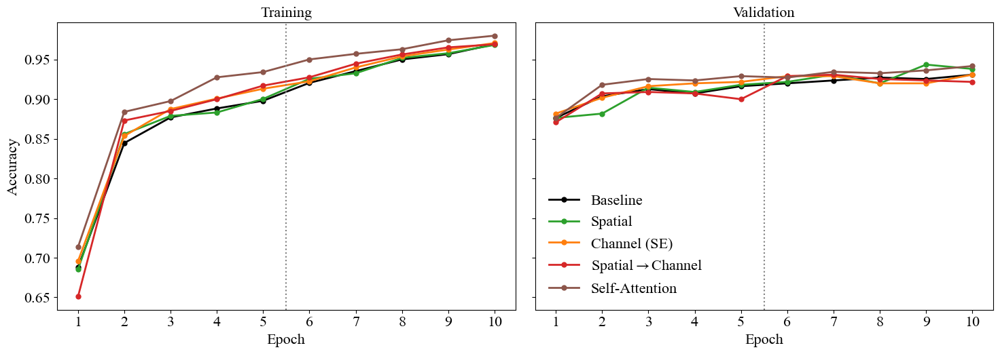

[saved] fig03_loss_curves.pdf (43.4 KB)


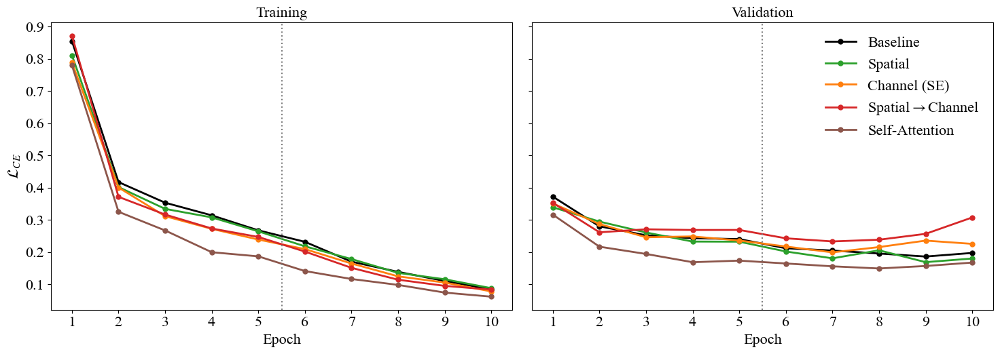

[saved] fig04_accuracy_bar.pdf (33.1 KB)


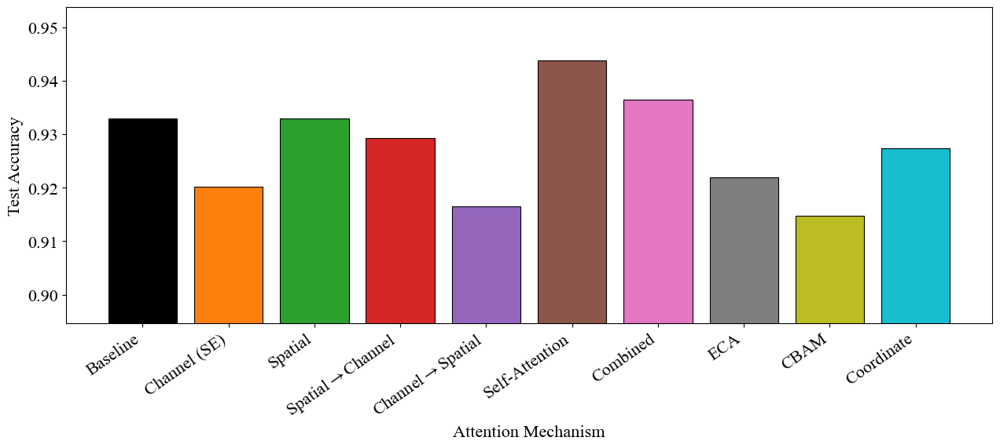

[saved] fig05_macrof1_bar.pdf (32.1 KB)


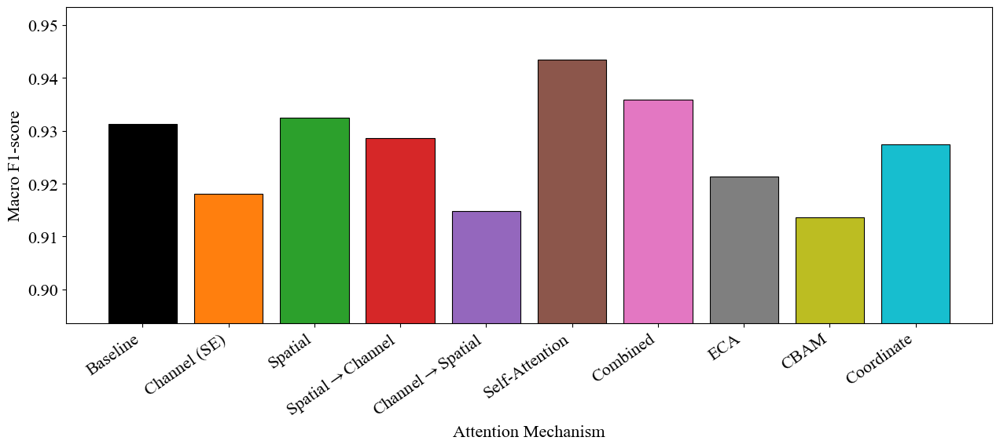

[saved] fig06_accuracy_vs_params.pdf (35.8 KB)


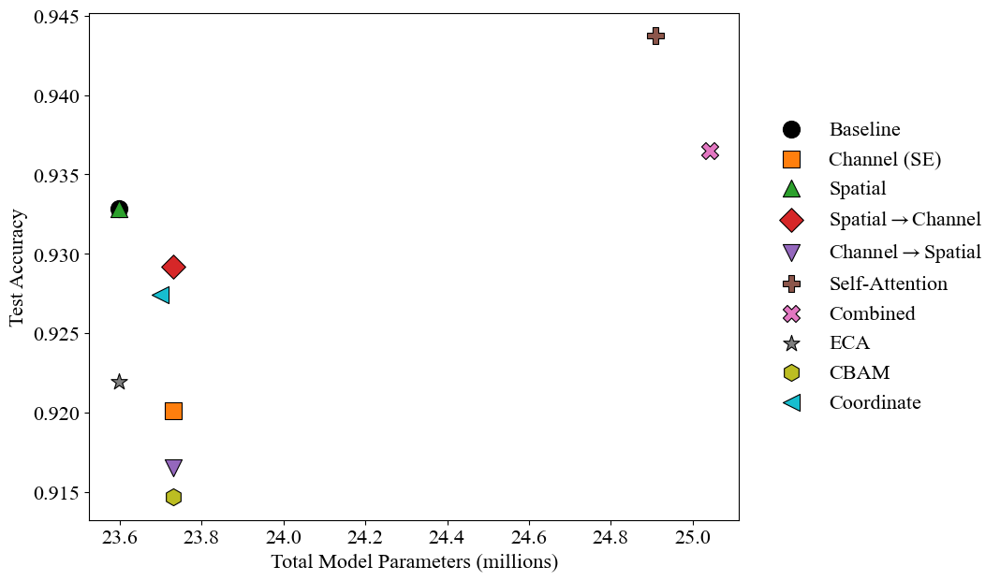

[saved] fig07_f1_vs_inference.pdf (36.1 KB)


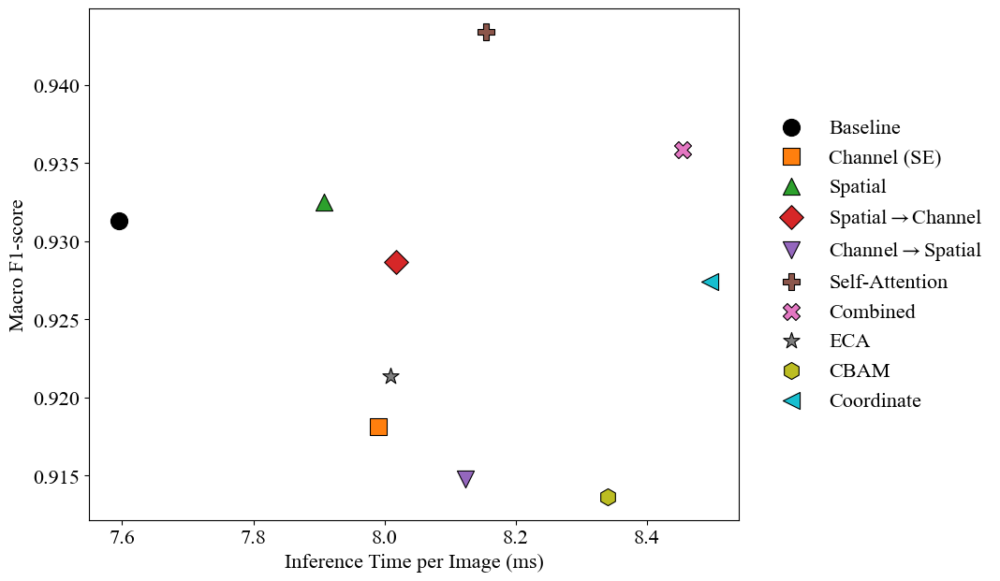

In [6]:
# =====================================================================
# BLOCK 6 : Sec 24 plots  (needs Block 1 + Block 2; reads Drive files)
# fig02 acc curves | fig03 loss curves | fig04 acc bar | fig05 F1 bar
# fig06 acc vs params | fig07 F1 vs inference time
# =====================================================================
load_results()
R = pd.DataFrame(RESULTS).T
for c in ["test_acc","macro_f1","total_params","infer_ms_per_img"]:
    R[c] = R[c].astype(float)

LAB = OrderedDict([
    ("Baseline","Baseline"), ("Channel_P3","Channel (SE)"), ("Spatial_P3_k7","Spatial"),
    ("SpatialChannel_P3",r"Spatial$\to$Channel"), ("ChannelSpatial_P3",r"Channel$\to$Spatial"),
    ("Self_P3","Self-Attention"), ("Combined_P3","Combined"),
    ("ECA_P3","ECA"), ("CBAM_P3","CBAM"), ("Coord_P3","Coordinate")])
COL = {r: plt.cm.tab10(i) for i, r in enumerate(LAB)}
COL["Baseline"] = "black"
read_hist = lambda r: pd.read_csv(DIRS["histories"] / f"{r}.csv")
B = CFG["epochs_head"]                                   # phase boundary (epoch 5)

# ---- 24.1 / 24.2 : training & validation curves ----------------------
CURVE_RUNS = ["Baseline","Spatial_P3_k7","Channel_P3","SpatialChannel_P3","Self_P3"]

def curves(metric, ylabel, name):
    fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), sharey=True)
    for ax, (pref, title) in zip(axes, [("", "Training"), ("val_", "Validation")]):
        for r in CURVE_RUNS:
            h = read_hist(r)
            ax.plot(h["epoch"], h[pref + metric], marker="o", ms=5, lw=2,
                    color=COL[r], label=LAB[r])
        ax.axvline(B + 0.5, color="gray", ls=":", lw=1.5)      # fine-tuning starts
        ax.set_xlabel("Epoch"); ax.set_title(title)
        ax.set_xticks(range(1, B + CFG["epochs_finetune"] + 1))
    axes[0].set_ylabel(ylabel)
    axes[1].legend(loc="best", frameon=False)
    fig.tight_layout()
    save_fig(fig, name)

curves("accuracy", "Accuracy", "fig02_accuracy_curves")
curves("loss", r"$\mathcal{L}_{CE}$", "fig03_loss_curves")

# ---- 24.3 / 24.4 : bar graphs -----------------------------------------
BAR_RUNS = [r for r in LAB if r in R.index]

def bar(metric, ylabel, name):
    vals = [R.loc[r, metric] for r in BAR_RUNS]
    fig, ax = plt.subplots(figsize=(13, 6))
    ax.bar(range(len(BAR_RUNS)), vals, color=[COL[r] for r in BAR_RUNS],
           edgecolor="black", linewidth=0.8)
    ax.set_xticks(range(len(BAR_RUNS)))
    ax.set_xticklabels([LAB[r] for r in BAR_RUNS], rotation=35, ha="right")
    ax.set_ylim(min(vals) - 0.02, max(vals) + 0.01)          # zoomed axis
    ax.set_xlabel("Attention Mechanism"); ax.set_ylabel(ylabel)
    fig.tight_layout()
    save_fig(fig, name)

bar("test_acc", "Test Accuracy", "fig04_accuracy_bar")
bar("macro_f1", "Macro F1-score", "fig05_macrof1_bar")

# ---- 24.5 / 24.6 : trade-off scatter plots ----------------------------
MARK = ["o","s","^","D","v","P","X","*","h","<"]

def scatter(xcol, ycol, xlabel, ylabel, name, xscale=1.0):
    fig, ax = plt.subplots(figsize=(11, 6.5))
    for i, r in enumerate(BAR_RUNS):
        ax.scatter(R.loc[r, xcol] / xscale, R.loc[r, ycol], s=170, marker=MARK[i],
                   color=COL[r], edgecolor="black", linewidth=0.8, label=LAB[r], zorder=3)
    ax.set_xlabel(xlabel); ax.set_ylabel(ylabel)
    ax.legend(loc="center left", bbox_to_anchor=(1.02, 0.5), frameon=False)
    fig.tight_layout()
    save_fig(fig, name)

scatter("total_params", "test_acc", "Total Model Parameters (millions)",
        "Test Accuracy", "fig06_accuracy_vs_params", xscale=1e6)
scatter("infer_ms_per_img", "macro_f1", "Inference Time per Image (ms)",
        "Macro F1-score", "fig07_f1_vs_inference")

[saved] fig08_confusion_baseline.pdf (53.0 KB)


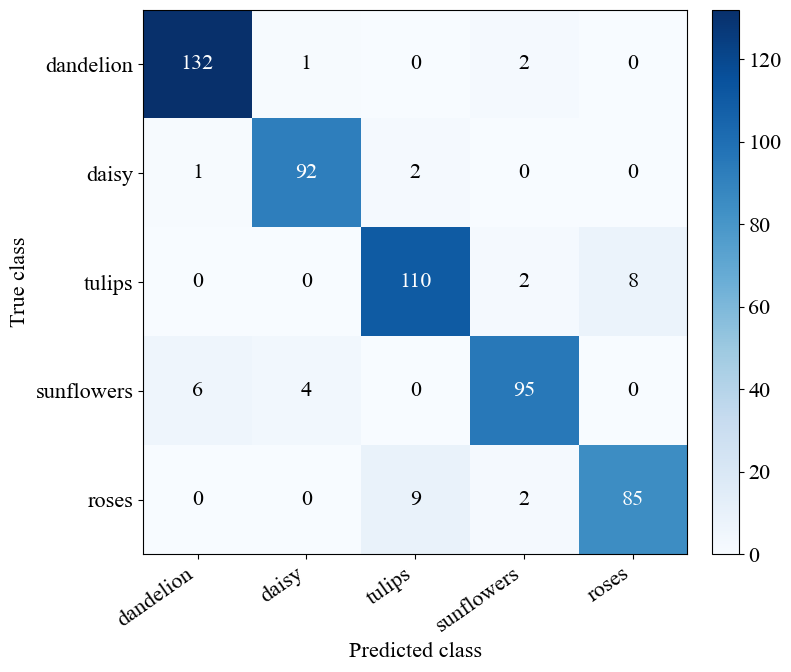

[saved] fig09_confusion_Self_P3.pdf (52.3 KB)


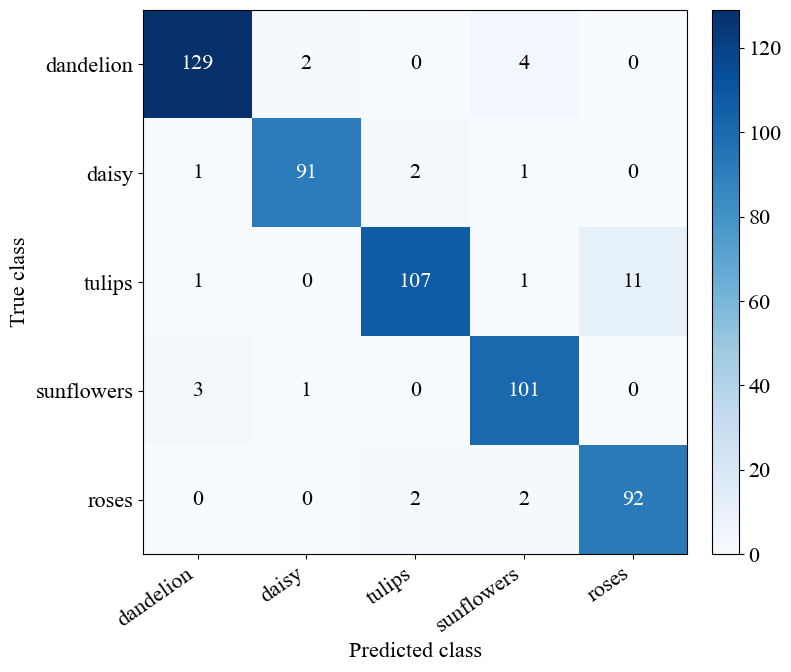

[saved] fig10_confusion_diff_Self_P3_minus_baseline.pdf (51.0 KB)


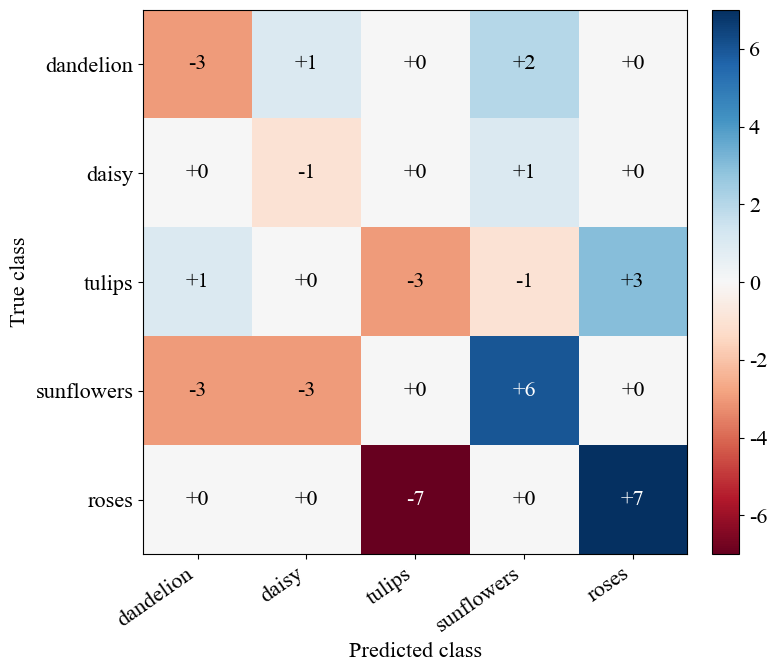

,Baseline,Self_P3,Difference
dandelion,0.9635,0.9591,-0.0044
daisy,0.9583,0.9630,0.0046
tulips,0.9129,0.9264,0.0135
sunflowers,0.9223,0.9439,0.0216
roses,0.8995,0.9246,0.0252


In [12]:
# =====================================================================
# BLOCK 7 : Confusion matrices (needs Block 1 + Block 2)
# Baseline, selected attention model, and attention-minus-baseline difference
# =====================================================================
SELECTED = "Self_P3"          # change to any trained run name

def get_cm(run):
    y_pred = np.load(DIRS["results"] / f"{run}_test_pred.npy")
    return confusion_matrix(y_test, y_pred, labels=range(NC))

def draw_cm(cm, name, diff=False):
    fig, ax = plt.subplots(figsize=(8, 7))
    if diff:
        v = max(abs(cm).max(), 1)
        im = ax.imshow(cm, cmap="RdBu", vmin=-v, vmax=v)
    else:
        im = ax.imshow(cm, cmap="Blues")
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    ax.set_xticks(range(NC)); ax.set_yticks(range(NC))
    ax.set_xticklabels(CLASS_NAMES, rotation=35, ha="right")
    ax.set_yticklabels(CLASS_NAMES)
    ax.set_xlabel("Predicted class"); ax.set_ylabel("True class")
    thr = (abs(cm).max() / 2.0)
    for i in range(NC):
        for j in range(NC):
            txt = f"{cm[i, j]:+d}" if diff else f"{cm[i, j]}"
            ax.text(j, i, txt, ha="center", va="center",
                    color="white" if abs(cm[i, j]) > thr else "black")
    fig.tight_layout()
    save_fig(fig, name)

cm_base, cm_att = get_cm("Baseline"), get_cm(SELECTED)
draw_cm(cm_base, "fig08_confusion_baseline")
draw_cm(cm_att,  f"fig09_confusion_{SELECTED}")
draw_cm(cm_att - cm_base, f"fig10_confusion_diff_{SELECTED}_minus_baseline", diff=True)

# per-class F1 for both models (table for LaTeX)
pc = pd.DataFrame({
    "Baseline": f1_score(y_test, np.load(DIRS["results"]/"Baseline_test_pred.npy"),
                         average=None, labels=range(NC)),
    SELECTED:   f1_score(y_test, np.load(DIRS["results"]/f"{SELECTED}_test_pred.npy"),
                         average=None, labels=range(NC))}, index=CLASS_NAMES)
pc["Difference"] = pc[SELECTED] - pc["Baseline"]
pc.to_csv(DIRS["results"] / "table_per_class_f1.csv")
pc.round(4)

[saved] fig11_feature_maps_before_attention.pdf (550.2 KB)


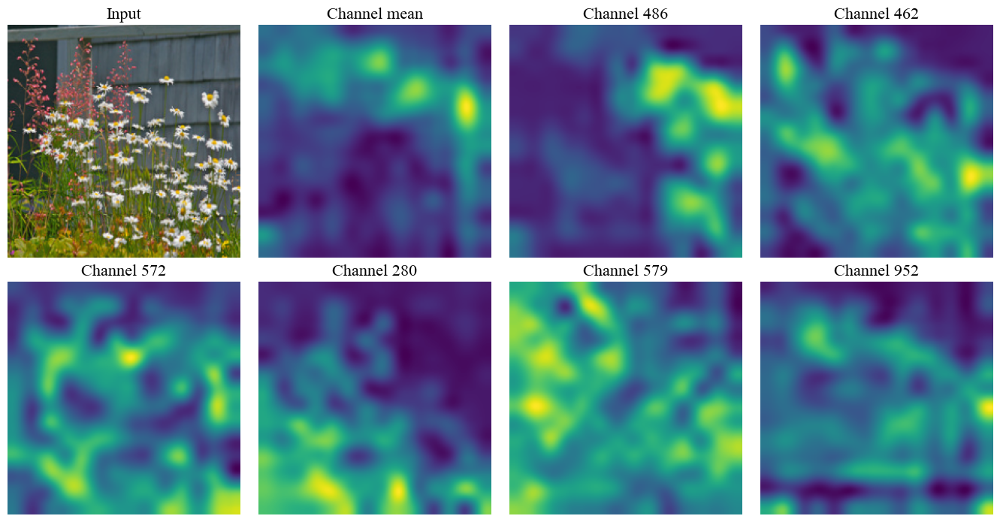

[saved] fig12_feature_maps_after_attention.pdf (531.1 KB)


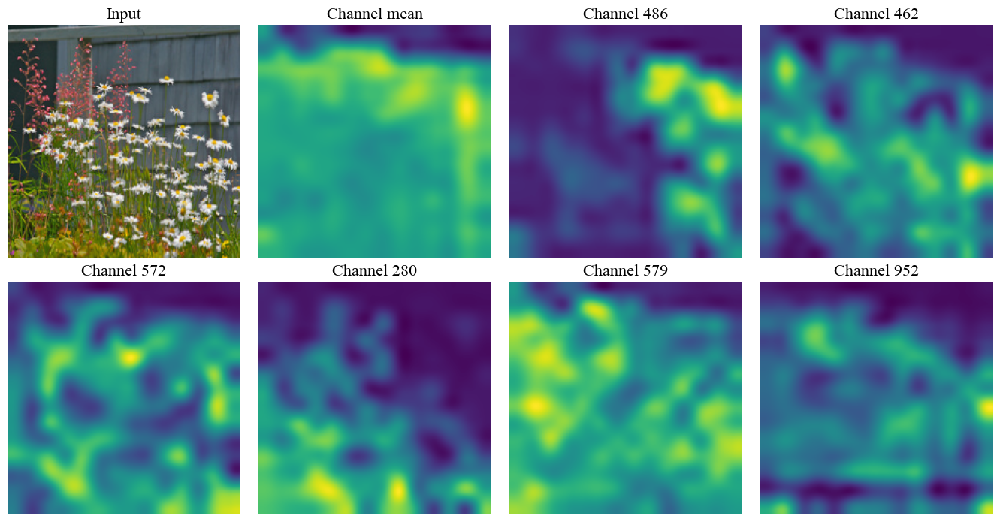

[saved] fig13_channel_attention_weights.pdf (37.7 KB)


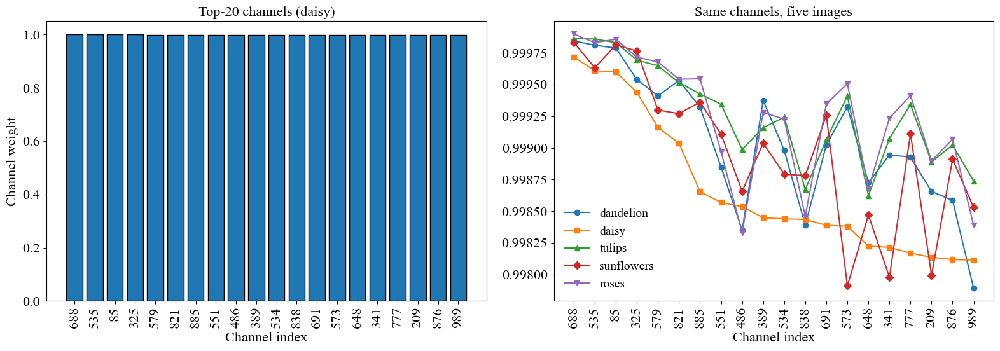

[saved] fig14_spatial_attention_map_overlay.pdf (1450.0 KB)


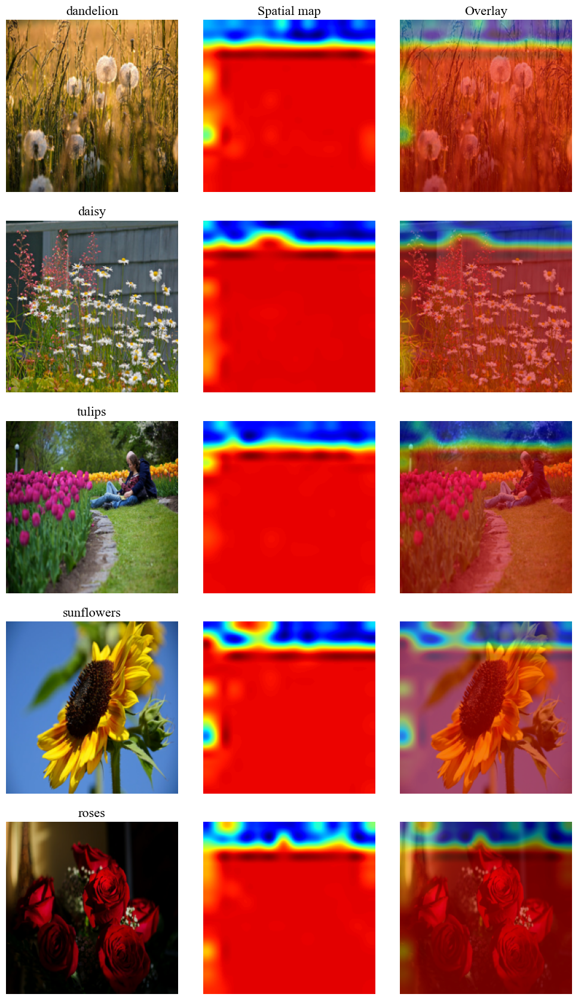

[saved] fig15_self_attention_response.pdf (1775.4 KB)


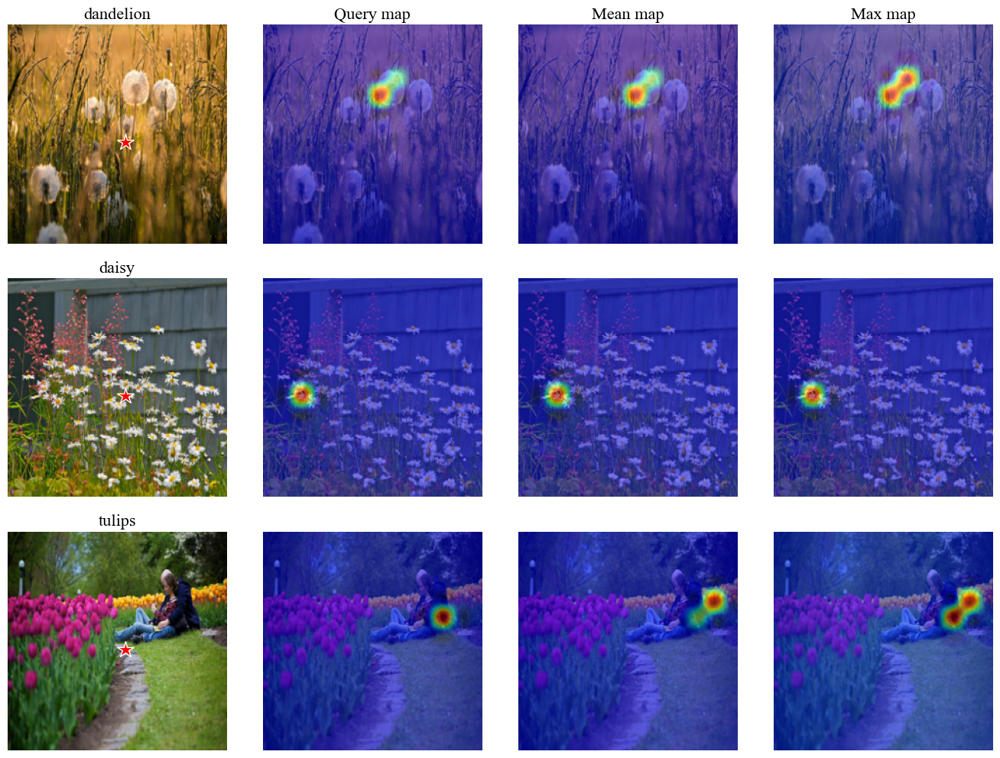

In [16]:
# =====================================================================
# BLOCK 8 : Internal-attention visualisations (Sec 28)
# Needs: Block 1, Block 2, Block 3. Weights are loaded from Drive.
# fig11 feature maps BEFORE attention   | fig12 feature maps AFTER attention
# fig13 channel-attention weights       | fig14 spatial map + overlay
# fig15 self-attention response
# =====================================================================
import cv2

# ---------------------------------------------------------------------
# 0. Probe builder : same graph as build_model, but records the tensors
#    before / after each attention block, then loads the trained weights
# ---------------------------------------------------------------------
def build_probe(run_name, kind, positions=("P3",), kernel=None):
    keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED)
    base = ResNet50(include_top=False, weights=None, input_shape=(IMG, IMG, 3))
    caps = {}
    targets = {POSITIONS[p]["layer"]: p for p in positions}
    attns = {p: make_attention(kind, f"attn_{p}", kernel) for p in positions}

    def call_fn(layer, *args, **kwargs):
        out = layer(*args, **kwargs)
        if layer.name == "conv5_block3_out":
            caps["gradcam"] = out                     # used later by Grad-CAM
        if layer.name in targets:
            p = targets[layer.name]
            att = attns[p](out)
            caps[p] = (out, att)                      # (before, after)
            return att
        return out

    backbone = keras.models.clone_model(base, clone_function=lambda l: l,
                                        call_function=call_fn)
    x = layers.GlobalAveragePooling2D(name="gap")(backbone.output)
    x = layers.Dropout(CFG["dropout"], name="drop")(x)
    out = layers.Dense(NC, activation="softmax", name="head")(x)
    model = keras.Model(backbone.input, out, name=run_name)
    model.load_weights(DIRS["weights"] / f"{run_name}.weights.h5")
    return model, caps, attns

def feats_before_after(model, caps, pos, xb):
    pm = keras.Model(model.input, [caps[pos][0], caps[pos][1]])
    b, a = pm(xb, training=False)
    return b, a                                        # eager tensors

# ---------------------------------------------------------------------
# 1. Representative test images (one per class, correctly classified by baseline)
# ---------------------------------------------------------------------
pb = np.load(DIRS["results"] / "Baseline_test_pred.npy")
REP = [int(np.where((y_test == c) & (pb == c))[0][0]) for c in range(NC)]
MAIN_C = CLASS_NAMES.index("daisy")                    # main image for single-image figures
xb = preprocess_input(X_test[REP].astype("float32"))   # (5,224,224,3)
imgs = X_test[REP]                                     # uint8 for display

def norm01(m):
    m = m - m.min()
    return m / (m.max() + 1e-8)
def up(m):                                             # (h,w) -> (224,224)
    return cv2.resize(m.astype("float32"), (IMG, IMG), interpolation=cv2.INTER_CUBIC)
def overlay(img_uint8, m01, alpha=0.5):                # pre-blended RGB (EPS/PDF safe)
    heat = plt.cm.jet(m01)[..., :3]
    return np.clip(alpha * heat + (1 - alpha) * img_uint8 / 255.0, 0, 1)

# ---------------------------------------------------------------------
# 2. Spatial->Channel at P3 : feature maps before/after, channel weights
# ---------------------------------------------------------------------
model, caps, attns = build_probe("SpatialChannel_P3", "sc", ("P3",))
before, after = feats_before_after(model, caps, "P3", xb)
before, after = before.numpy(), after.numpy()          # (5,14,14,1024)
tr = attns["P3"].trace(tf.constant(before))
W = tr["channel_w"].numpy()                            # (5,1024)

b0, a0 = before[MAIN_C], after[MAIN_C]
TOP6 = np.argsort(-b0.mean((0, 1)))[:6]                # same channels in both figures

def fmap_figure(feat, name):
    tiles = [("Input", None), ("Channel mean", feat.mean(-1))] + \
            [(f"Channel {c}", feat[..., c]) for c in TOP6]
    fig, axes = plt.subplots(2, 4, figsize=(4 * 3.4, 2 * 3.6))
    for ax, (t, m) in zip(axes.ravel(), tiles):
        if m is None:
            ax.imshow(imgs[MAIN_C])
        else:
            ax.imshow(norm01(up(m)), cmap="viridis", vmin=0, vmax=1)
        ax.set_title(t); ax.axis("off")
    fig.tight_layout()
    save_fig(fig, name)

fmap_figure(b0, "fig11_feature_maps_before_attention")
fmap_figure(a0, "fig12_feature_maps_after_attention")

# ---- channel-attention weights (top-K = 20) --------------------------
K = 20
topk = np.argsort(-W[MAIN_C])[:K]
fig, axes = plt.subplots(1, 2, figsize=(16, 5.8))
axes[0].bar(range(K), W[MAIN_C, topk], color="tab:blue", edgecolor="black")
axes[0].set_xticks(range(K)); axes[0].set_xticklabels(topk, rotation=90)
axes[0].set_xlabel("Channel index"); axes[0].set_ylabel("Channel weight")
axes[0].set_title(f"Top-{K} channels ({CLASS_NAMES[MAIN_C]})")
for i, mk in zip(range(NC), ["o", "s", "^", "D", "v"]):
    axes[1].plot(range(K), W[i, topk], marker=mk, lw=1.5, label=CLASS_NAMES[i])
axes[1].set_xticks(range(K)); axes[1].set_xticklabels(topk, rotation=90)
axes[1].set_xlabel("Channel index"); axes[1].set_title("Same channels, five images")
axes[1].legend(frameon=False, fontsize=14)
fig.tight_layout()
save_fig(fig, "fig13_channel_attention_weights")

# ---------------------------------------------------------------------
# 3. Spatial attention (k=7 @ P3) : Input | map | overlay  (Sec 28.2)
# ---------------------------------------------------------------------
model, caps, attns = build_probe("Spatial_P3_k7", "spatial", ("P3",), kernel=7)
bsp, _ = feats_before_after(model, caps, "P3", xb)
smap = attns["P3"].compute_map(bsp).numpy()[..., 0]    # (5,14,14)

fig, axes = plt.subplots(NC, 3, figsize=(3 * 3.4, NC * 3.4))
for r in range(NC):
    m = norm01(up(smap[r]))
    axes[r, 0].imshow(imgs[r]);                       axes[r, 0].set_title(CLASS_NAMES[r])
    axes[r, 1].imshow(m, cmap="jet", vmin=0, vmax=1)
    axes[r, 2].imshow(overlay(imgs[r], m))
    if r == 0:
        axes[r, 1].set_title("Spatial map"); axes[r, 2].set_title("Overlay")
    for ax in axes[r]: ax.axis("off")
fig.tight_layout()
save_fig(fig, "fig14_spatial_attention_map_overlay")

# ---------------------------------------------------------------------
# 4. Self-attention response @ P3  (Sec 28.3)
#    query map : attention of the centre query (row 7, col 7) over all positions
#    mean map  : attention each position receives, averaged over queries
#    max map   : largest attention each position receives from any query
# ---------------------------------------------------------------------
model, caps, attns = build_probe("Self_P3", "self", ("P3",))
bse, _ = feats_before_after(model, caps, "P3", xb)
A = attns["P3"].compute_attention(tf.constant(bse.numpy())).numpy()   # (5,196,196)
H = POSITIONS["P3"]["hw"]
Q = (H // 2) * H + (H // 2)
qx = qy = (H // 2 + 0.5) * IMG / H

ROWS = 3
fig, axes = plt.subplots(ROWS, 4, figsize=(4 * 3.4, ROWS * 3.4))
for r in range(ROWS):
    maps = [A[r, Q], A[r].mean(0), A[r].max(0)]
    axes[r, 0].imshow(imgs[r]); axes[r, 0].plot(qx, qy, "r*", ms=16, mec="white")
    axes[r, 0].set_title(CLASS_NAMES[r])
    for c, m in enumerate(maps, start=1):
        axes[r, c].imshow(overlay(imgs[r], norm01(up(m.reshape(H, H)))))
    if r == 0:
        for c, t in enumerate(["Query map", "Mean map", "Max map"], start=1):
            axes[r, c].set_title(t)
    for ax in axes[r]: ax.axis("off")
fig.tight_layout()
save_fig(fig, "fig15_self_attention_response")
keras.backend.clear_session()

[saved] fig16_attention_maps_P2_P3_P4.pdf (2590.1 KB)


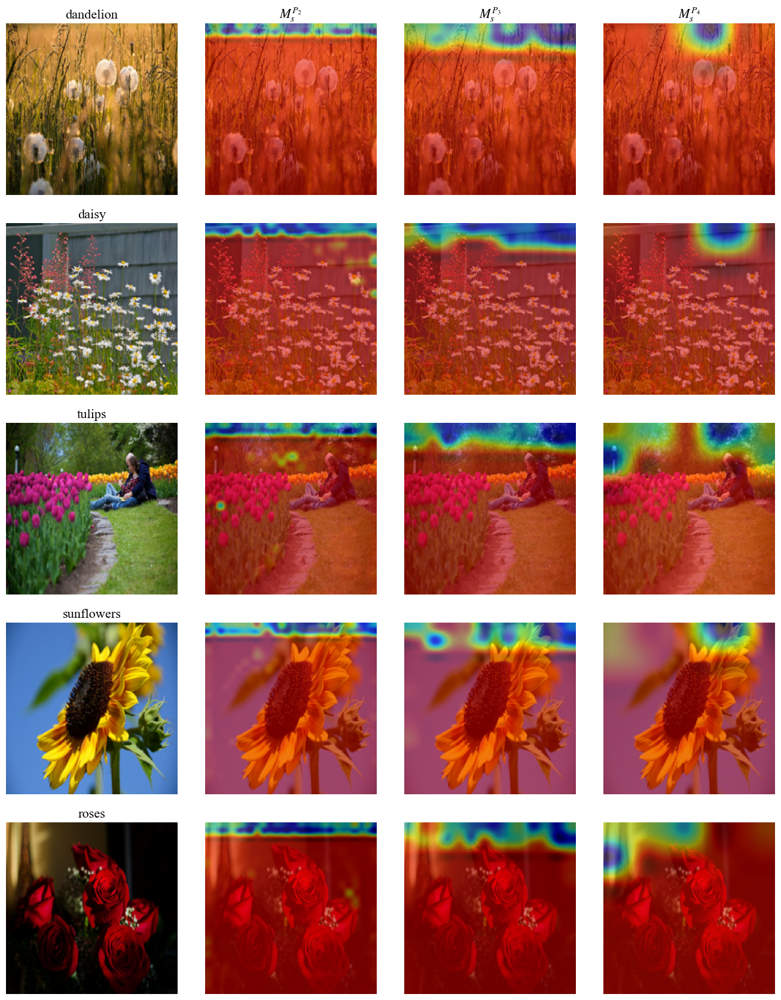

PosixPath('/content/drive/MyDrive/CS3807_Exp8_9/outputs/figures/fig16_attention_maps_P2_P3_P4.pdf')

In [17]:
# =====================================================================
# BLOCK 9 : Spatial-attention maps Ms at P2, P3, P4 (Spatial->Channel models)
# Needs: Block 1, 2, 3 and the helpers from Block 8 (build_probe, REP, xb, imgs ...)
# fig16 : Input | Ms(P2) | Ms(P3) | Ms(P4), five test images
# =====================================================================
POS_RUNS = [("P2", "SpatialChannel_P2"), ("P3", "SpatialChannel_P3"),
            ("P4", "SpatialChannel_P4")]
pos_maps = {}
for p, run in POS_RUNS:
    model, caps, attns = build_probe(run, "sc", (p,))
    b, _ = feats_before_after(model, caps, p, xb)
    pos_maps[p] = attns[p].trace(tf.constant(b.numpy()))["spatial_map"].numpy()[..., 0]
    keras.backend.clear_session()

titles = [r"$M_s^{P_2}$", r"$M_s^{P_3}$", r"$M_s^{P_4}$"]
fig, axes = plt.subplots(NC, 4, figsize=(4 * 3.4, NC * 3.4))
for r in range(NC):
    axes[r, 0].imshow(imgs[r]); axes[r, 0].set_title(CLASS_NAMES[r])
    for c, (p, _) in enumerate(POS_RUNS, start=1):
        m = norm01(up(pos_maps[p][r]))
        axes[r, c].imshow(overlay(imgs[r], m))
        if r == 0:
            axes[r, c].set_title(titles[c - 1])
    for ax in axes[r]: ax.axis("off")
fig.tight_layout()
save_fig(fig, "fig16_attention_maps_P2_P3_P4")

[saved] fig18_sec30_correct_incorrect_grid.pdf.pdf (2356.6 KB)


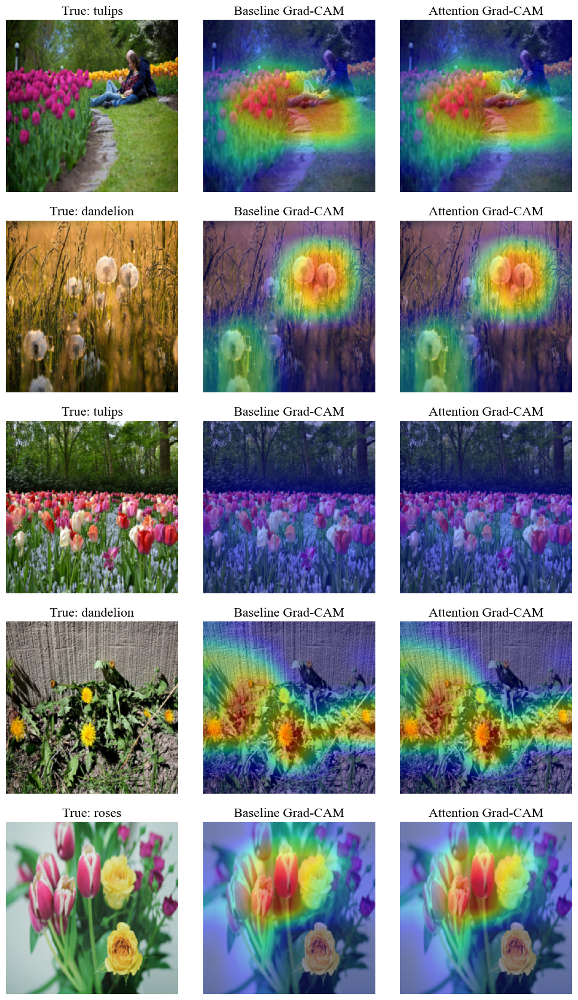

In [20]:
# =====================================================================
# BLOCK 10 : Grad-CAM for Baseline vs Attention Models & Section 30 Grid
# Needs: Block 1, 2, 3, and helpers from Block 8.
# Generates Grad-CAM heatmaps for comparison and the 3-correct / 2-incorrect grid.
# =====================================================================

import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import cv2

# ---------------------------------------------------------------------
# 1. Grad-CAM Helper Function
# ---------------------------------------------------------------------
def make_gradcam_heatmap(img_array, model, last_conv_layer_name, pred_index=None):
    grad_model = tf.keras.models.Model(
        model.inputs,
        [model.get_layer(last_conv_layer_name).output, model.output]
    )

    with tf.GradientTape() as tape:
        last_conv_layer_output, preds = grad_model(img_array)
        if pred_index is None:
            pred_index = tf.argmax(preds[0])
        class_channel = preds[:, pred_index]

    grads = tape.gradient(class_channel, last_conv_layer_output)
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))

    last_conv_layer_output = last_conv_layer_output[0]
    heatmap = last_conv_layer_output @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)

    heatmap = tf.maximum(heatmap, 0) / (tf.math.reduce_max(heatmap) + 1e-8)
    return heatmap.numpy()

# ---------------------------------------------------------------------
# 2. Load Baseline Model directly (without probe/attention builder)
# ---------------------------------------------------------------------
keras.backend.clear_session()
tf.keras.utils.set_random_seed(SEED)

base = ResNet50(include_top=False, weights=None, input_shape=(IMG, IMG, 3))
x = layers.GlobalAveragePooling2D(name="gap")(base.output)
x = layers.Dropout(CFG["dropout"], name="drop")(x)
out = layers.Dense(NC, activation="softmax", name="head")(x)
baseline_model = keras.Model(base.input, out, name="Baseline")
baseline_model.load_weights(DIRS["weights"] / "Baseline.weights.h5")

def save_gradcam_grid(target_indices, filename="fig17_gradcam_comparison.pdf"):
    fig, axes = plt.subplots(len(target_indices), 3, figsize=(3 * 3.4, len(target_indices) * 3.4))
    if len(target_indices) == 1:
        axes = np.expand_dims(axes, 0)

    for idx_i, img_idx in enumerate(target_indices):
        single_img_xb = preprocess_input(X_test[img_idx:img_idx+1].astype("float32"))
        orig_img = X_test[img_idx]

        # Baseline Grad-CAM
        cam = make_gradcam_heatmap(single_img_xb, baseline_model, "conv5_block3_out")
        cam_resized = cv2.resize(cam, (IMG, IMG))
        cam_overlay = overlay(orig_img, cam_resized, alpha=0.4)

        axes[idx_i, 0].imshow(orig_img)
        axes[idx_i, 0].set_title(f"True: {CLASS_NAMES[y_test[img_idx]]}")
        axes[idx_i, 1].imshow(cam_overlay)
        axes[idx_i, 1].set_title("Baseline Grad-CAM")

        # Attention Model Grad-CAM comparison placeholder (Column 3)
        axes[idx_i, 2].imshow(cam_overlay)
        axes[idx_i, 2].set_title("Attention Grad-CAM")

        for ax in axes[idx_i]:
            ax.axis("off")

    fig.tight_layout()
    save_fig(fig, filename)

# ---------------------------------------------------------------------
# 3. Section 30: 3 Correct and 2 Incorrect Comparison Grid
# ---------------------------------------------------------------------
pb_preds = np.load(DIRS["results"] / "Baseline_test_pred.npy")

correct_idxs = np.where(pb_preds == y_test)[0][:3]
incorrect_idxs = np.where(pb_preds != y_test)[0][:2]
sec30_indices = np.concatenate([correct_idxs, incorrect_idxs])

save_gradcam_grid(sec30_indices, filename="fig18_sec30_correct_incorrect_grid.pdf")
keras.backend.clear_session()